# 深圳五一共享单车的 72 小时

## 318 万次骑行背后的城市时空图谱

**数据**：2021-05-01 至 05-03 深圳市共享单车脱敏订单，原始 3,364,413 条  
**方法**：地理网格 · OD 网络 · 社区发现 · 无监督聚类 · 梯度提升树  
**产出**：三天三套节律、14 个骑行社区、潮汐失衡清单、1 小时前瞻需求预测

---

### 摘要

我们用 336 万条订单重建了深圳在一个假期里的骑行行为。清理后保留 **318.9 万次**有效骑行，累计 **390.8 万公里**，相当于绕赤道 97 圈。主要结论：

| # | 发现 | 关键数字 |
|---|------|----------|
| 1 | 同一个假期，三天是三套剧本 | 5/1 共 127.9 万次、18 点单小时 9.6 万次；5/3 傍晚反弹至 8.9 万次/小时 |
| 2 | 5/2 16:10 前后，全市骑行在 80 分钟内下降 60% | 35 个片区中 33 个同步下跌，全市 17 点/15 点比值 0.44 |
| 3 | 骑行是"最后两公里"的生意 | 中位距离 900 m、中位时长 9.6 分钟，86% 的骑行不超过 2 km |
| 4 | 城市由 14 个强内聚的骑行社区组成 | 网络模块度 0.833，96% 的骑行不跨社区 |
| 5 | 早高峰向就业中心汇聚，晚高峰反向流出 | 2 公里块单小时最大净流入 +456 辆/天，最大净流出 −563 辆/天 |
| 6 | 1 小时前瞻需求可以预测得相当准 | 网格级 MAE 10.3 辆，较历史均值基线下降 24%，R² = 0.91 |

---

### 目录

1. [研究背景与问题](#1-研究背景与问题)
2. [数据字典与加载](#2-数据字典与加载)
3. [数据质量审计](#3-数据质量审计)
4. [清洗流程](#4-清洗流程)
5. [特征工程](#5-特征工程)
6. [时间维度：三天三套剧本](#6-时间维度三天三套剧本)
7. [空间维度：城市的热力骨架](#7-空间维度城市的热力骨架)
8. [距离、时长与速度](#8-距离时长与速度)
9. [OD 流向：谁在给谁输血](#9-od-流向谁在给谁输血)
10. [骑行社区：用图算法切分城市](#10-骑行社区用图算法切分城市)
11. [功能区聚类：时间形态识别](#11-功能区聚类时间形态识别)
12. [潮汐与供需失衡](#12-潮汐与供需失衡)
13. [用户行为](#13-用户行为)
14. [需求预测建模](#14-需求预测建模)
15. [结论与运营建议](#15-结论与运营建议)
16. [局限与后续工作](#16-局限与后续工作)

## 1. 研究背景与问题

共享单车是少数能同时记录 **"谁、在什么时间、从哪到哪"** 的城市级数据源。它的每一次开锁和关锁，都是一个带时间戳的空间点对。把几百万个这样的点对叠在一起，得到的不只是出行统计，而是一张城市在特定时段里的活动地图。

2021 年五一假期是一个很有观察价值的窗口：

- 它是五天长假，深圳作为移民城市，假期的人口流动剧烈；
- 假期出行剥离了"通勤"这个最强的规律性因素，让**休闲、消费、探亲、接驳**等动机浮出水面；
- 三天里恰好包含一次天气扰动（5 月 2 日下午），给了我们一个天然的"对照实验"。

本报告围绕四个问题展开：

1. **节律**：假期的骑行时间结构长什么样？三天之间是否一致？
2. **空间**：骑行热点在哪里？它们如何随时间迁移？
3. **流动**：起终点之间的流量网络呈现什么结构？城市可以被切成几个"骑行单元"？
4. **失衡**：哪些地方、哪些时段车辆淤积或缺车？能否提前预测？

分析链路如下：

```
原始订单 → 质量审计 → 清洗规则 → 特征工程
        → 时间序列 / 空间热力 / OD 网络
        → 社区发现（Louvain） / 功能聚类（KMeans）
        → 潮汐失衡识别 → 需求预测（HistGradientBoosting） → 运营建议
```

> 说明：本报告的所有结论都由下方代码实时计算得出，图表中的数字与正文一致。数据中的 `USER_ID` 为脱敏哈希值，无法还原到个人。

In [1]:
%matplotlib inline
# ============================================================
# 环境初始化：依赖、中文字体、配色与通用工具
# ============================================================
import os
import gc
import glob
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.colors
import matplotlib.ticker
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.collections import LineCollection
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---- 中文字体：兼容本地 Windows 与和鲸 / ModelWhale (Linux) ----
CJK_CANDIDATES = [
    "Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Noto Sans SC",
    "Source Han Sans SC", "WenQuanYi Zen Hei", "PingFang SC", "Arial Unicode MS",
]
available_fonts = {f.name for f in fm.fontManager.ttflist}
CJK_FONTS = [f for f in CJK_CANDIDATES if f in available_fonts]

plt.rcParams["font.sans-serif"] = CJK_FONTS + ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#C9D2DA",
    "axes.linewidth": 0.8,
    "xtick.color": "#5C6B7A",
    "ytick.color": "#5C6B7A",
    "text.color": "#12232E",
})

print(f"中文字体: {CJK_FONTS[0] if CJK_FONTS else '未找到（中文可能显示异常）'}")
print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

中文字体: Microsoft YaHei
pandas 2.3.0 | numpy 2.3.5 | matplotlib 3.10.3


In [2]:
# ============================================================
# 全局配色与绘图工具
# 统一的视觉语言：墨色正文 + 青绿主色 + 珊瑚强调色
# ============================================================
C = {
    "ink":    "#12232E",
    "muted":  "#6B7B8C",
    "grid":   "#E6EBEF",
    "line":   "#C9D2DA",
    "teal":   "#0E6A75",
    "teal2":  "#3FA7A3",
    "teal3":  "#8FC9C4",
    "mint":   "#D7EDEB",
    "coral":  "#D9532B",
    "gold":   "#E8A33D",
    "sand":   "#F4EDE4",
    "blue":   "#1F5FA8",
}

CMAP_TEAL = LinearSegmentedColormap.from_list(
    "teal", ["#F8FBFC", "#D7EDEB", "#8FC9C4", "#3FA7A3", "#0E6A75", "#06363D"]
)
CMAP_WARM = LinearSegmentedColormap.from_list(
    "warm", ["#FFF8F0", "#FBE0C4", "#F0BC8E", "#E8A33D", "#D9532B", "#7A2410"]
)
CMAP_DIV = LinearSegmentedColormap.from_list(
    "div", ["#15538F", "#5C93C8", "#C7D8E8", "#F7F5F0", "#F0C3A4", "#D9532B", "#8E2A12"]
)


def style_ax(ax, grid_axis="y"):
    """统一的坐标轴风格：去掉上/右边框，保留浅色网格。"""
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(C["line"])
    ax.tick_params(colors=C["muted"], labelsize=9.5, length=3)
    if grid_axis:
        ax.grid(axis=grid_axis, color=C["grid"], lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    return ax


def fig_header(fig, title, subtitle=None, x=0.055, y=0.985):
    """图题 + 副标题，左对齐。"""
    fig.text(x, y, title, fontsize=15.5, fontweight="bold", color=C["ink"],
             ha="left", va="top")
    if subtitle:
        fig.text(x, y - 0.052, subtitle, fontsize=10, color=C["muted"],
                 ha="left", va="top")


def fig_footer(fig, text, x=0.055):
    """图注：数据来源与计算口径。"""
    fig.text(x, 0.012, text, fontsize=8.3, color=C["muted"], ha="left", va="bottom")


def fmt_wan(x, digits=1):
    """把大数格式化为“万”。"""
    return f"{x / 1e4:,.{digits}f} 万"

In [3]:
# ============================================================
# 空间计算工具：球面距离、网格化、片区近似归属
# ============================================================
GRID = 0.01          # 网格边长（约 1.1 km）
SHENZHEN_BBOX = (22.39, 22.87, 113.75, 114.63)   # (lat_min, lat_max, lng_min, lng_max)


def haversine(lat1, lon1, lat2, lon2, radius=6_371_000.0):
    """向量化 Haversine 距离，单位：米。"""
    lat1, lon1 = np.radians(np.asarray(lat1, dtype=float)), np.radians(np.asarray(lon1, dtype=float))
    lat2, lon2 = np.radians(np.asarray(lat2, dtype=float)), np.radians(np.asarray(lon2, dtype=float))
    dphi = lat2 - lat1
    dlambda = lon2 - lon1
    a = np.sin(dphi / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlambda / 2) ** 2
    return 2 * radius * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


# 深圳主要片区的近似中心点（用于把网格映射成人类可读的地名，精度约 ±1~2 km）
ANCHORS = {
    "罗湖·东门": (22.548, 114.118), "罗湖·国贸": (22.539, 114.118),
    "罗湖·人民南": (22.552, 114.108), "罗湖·布心": (22.580, 114.140),
    "罗湖·莲塘": (22.565, 114.170),
    "福田·CBD": (22.538, 114.058), "福田·车公庙": (22.536, 114.026),
    "福田·华强北": (22.546, 114.088), "福田·梅林": (22.568, 114.048),
    "福田·上沙": (22.523, 114.038), "福田·石厦": (22.518, 114.058),
    "福田·皇岗": (22.525, 114.070), "福田·香蜜湖": (22.548, 114.030),
    "南山·科技园": (22.540, 113.953), "南山·后海": (22.515, 113.936),
    "南山·南油": (22.520, 113.918), "南山·蛇口": (22.489, 113.918),
    "南山·西丽": (22.590, 113.960), "南山·前海": (22.532, 113.897),
    "南山·大冲": (22.545, 113.970), "南山·白石洲": (22.538, 113.980),
    "宝安·新安": (22.560, 113.885), "宝安·西乡": (22.575, 113.860),
    "宝安·福永": (22.670, 113.820), "宝安·沙井": (22.730, 113.800),
    "宝安·松岗": (22.770, 113.830), "宝安·石岩": (22.680, 113.930),
    "光明·光明": (22.755, 113.935), "光明·公明": (22.780, 113.900),
    "龙华·龙华": (22.655, 114.030), "龙华·民治": (22.625, 114.040),
    "龙华·观澜": (22.715, 114.055),
    "龙岗·坂田": (22.630, 114.070), "龙岗·布吉": (22.605, 114.120),
    "龙岗·横岗": (22.640, 114.190), "龙岗·龙岗中心城": (22.720, 114.247),
    "龙岗·平湖": (22.690, 114.120), "龙岗·坪地": (22.760, 114.300),
    "坪山·坪山": (22.690, 114.350),
    "盐田·沙头角": (22.555, 114.235), "盐田·梅沙": (22.595, 114.310),
    "大鹏·大鹏": (22.590, 114.470),
}

_ANCHOR_NAMES = np.array(list(ANCHORS))
_ANCHOR_XY = np.array(list(ANCHORS.values()), dtype=float)


def area_label(lat, lng):
    """返回每个坐标最近的片区名称及其距离（km）。"""
    lat = np.atleast_1d(np.asarray(lat, dtype=float))
    lng = np.atleast_1d(np.asarray(lng, dtype=float))
    dlat = (_ANCHOR_XY[None, :, 0] - lat[:, None]) * 111.0
    dlng = (_ANCHOR_XY[None, :, 1] - lng[:, None]) * 111.0 * np.cos(np.radians(22.6))
    dist = np.hypot(dlat, dlng)
    idx = dist.argmin(axis=1)
    return _ANCHOR_NAMES[idx], dist[np.arange(len(idx)), idx]


def grid_center(y, x, step=GRID):
    """网格行列号 → 网格中心经纬度。"""
    return (np.asarray(y) + 0.5) * step, (np.asarray(x) + 0.5) * step

## 2. 数据字典与加载

### 2.1 字段说明

| 字段 | 含义 | 示例 | 说明 |
|---|---|---|---|
| `START_TIME` | 开锁时间 | `2021-05-01 00:00:00.0` | 精度到秒，毫秒位恒为 0 |
| `END_TIME` | 关锁时间 | `2021-05-01 00:00:11.0` | 可跨日，最晚到 05-04 03:59 |
| `START_LAT` / `START_LNG` | 起点纬度 / 经度 | `22.52815664` / `113.91776357` | WGS-84，约 7 位小数 |
| `END_LAT` / `END_LNG` | 终点纬度 / 经度 | `22.5275906` / `113.91823034` | 同上 |
| `USER_ID` | 用户标识 | `063874bf95a4c1b7ccf9d1******` | 前 22 位哈希 + 10 个掩码字符 |
| `COM_ID` | 所属企业 / 社区 ID | 空 | 整列为空，后续剔除 |

### 2.2 加载策略

数据量 3.36 百万行、432 MB。加载阶段做三件事控制内存与耗时：

1. **显式声明 dtype**，坐标用 `float64`（`float32` 在 7 位小数上会丢精度，影响坐标级审计）；
2. **用户 ID 立即整数化**：`factorize` 成 `int32`，把约 400 MB 的字符串对象压缩到 13 MB；
3. **一次性计算派生量**（时长、距离、速度），避免后续重复扫描。

数据路径支持三种方式，按优先级：环境变量 `BIKE_DATA_PATH` → 当前目录 → 和鲸挂载目录 `/home/mw/input/**` 递归查找。

In [4]:
DATA_FILENAME = "bike_orders_20210501_20210503.csv"
MANUAL_PATH = None      # 自动查找失败时，直接在这里填绝对路径


def find_data(filename=DATA_FILENAME, manual=None):
    """在常见位置查找数据文件，适配本地与和鲸 / ModelWhale 环境。"""
    if manual and os.path.isfile(manual):
        return os.path.abspath(manual)
    candidates = []
    if os.environ.get("BIKE_DATA_PATH"):
        candidates.append(os.environ["BIKE_DATA_PATH"])
    candidates += [filename, os.path.join(os.getcwd(), filename)]
    for root in ("/home/mw/input", "/home/mw/inputs", "/home/mw/data", "/home/jovyan", "."):
        if os.path.isdir(root):
            candidates += sorted(glob.glob(os.path.join(root, "**", filename), recursive=True))[:3]
    for path in candidates:
        if path and os.path.isfile(path):
            return os.path.abspath(path)
    raise FileNotFoundError(
        f"未找到 {filename}。\n"
        "请将数据挂载到 /home/mw/input/ 下，或设置环境变量 BIKE_DATA_PATH，"
        "或修改本单元格的 MANUAL_PATH。"
    )


DTYPES = {
    "START_TIME": "string", "END_TIME": "string",
    "START_LAT": "float64", "START_LNG": "float64",
    "END_LAT": "float64", "END_LNG": "float64",
    "USER_ID": "string", "COM_ID": "string",
}


def load_orders(path):
    """读取原始订单并完成基础派生，返回精简后的 DataFrame。"""
    t0 = time.time()
    raw = pd.read_csv(path, dtype=DTYPES, encoding="utf-8-sig")

    df = pd.DataFrame({
        "start_time": pd.to_datetime(raw["START_TIME"], format="%Y-%m-%d %H:%M:%S.%f"),
        "end_time":   pd.to_datetime(raw["END_TIME"],   format="%Y-%m-%d %H:%M:%S.%f"),
        "start_lat":  raw["START_LAT"],
        "start_lng":  raw["START_LNG"],
        "end_lat":    raw["END_LAT"],
        "end_lng":    raw["END_LNG"],
    })
    # 用户 ID 整数化：保留唯一性，丢掉 32 字节字符串带来的内存开销
    df["user_code"] = pd.factorize(raw["USER_ID"])[0].astype("int32")
    df["duration_s"] = (df["end_time"] - df["start_time"]).dt.total_seconds()
    df["distance_m"] = haversine(df["start_lat"], df["start_lng"], df["end_lat"], df["end_lng"])
    df["speed_ms"] = df["distance_m"] / df["duration_s"].where(df["duration_s"] > 0)

    com_missing = raw["COM_ID"].isna().mean()
    del raw
    gc.collect()

    print(f"读入 {len(df):,} 行 × {df.shape[1]} 列，耗时 {time.time() - t0:.1f}s")
    print(f"内存占用 {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
    print(f"COM_ID 缺失率 {com_missing:.4%}（整列为空，后续剔除）")
    return df


DATA_PATH = find_data(manual=MANUAL_PATH)
print("数据文件:", DATA_PATH)
df = load_orders(DATA_PATH)

数据文件: D:\作业\和鲸社区项目\深圳五一共享单车\bike_orders_20210501_20210503.csv


读入 3,364,413 行 × 10 列，耗时 7.4s
内存占用 244 MB
COM_ID 缺失率 100.0000%（整列为空，后续剔除）


In [5]:
# 数据概览
overview = pd.DataFrame({
    "列名": df.columns,
    "非空数": [df[c].notna().sum() for c in df.columns],
    "缺失率": [f"{df[c].isna().mean():.2%}" for c in df.columns],
    "类型": [str(df[c].dtype) for c in df.columns],
})
display(overview)
display(df.head(5))

print(f"时间跨度：{df.start_time.min():%Y-%m-%d %H:%M:%S}  →  {df.end_time.max():%Y-%m-%d %H:%M:%S}")
print(f"唯一用户：{df.user_code.nunique():,}")
print(f"骑行距离：中位数 {df.distance_m.median():,.0f} m，均值 {df.distance_m.mean():,.0f} m")
print(f"骑行时长：中位数 {df.duration_s.median():,.0f} s，均值 {df.duration_s.mean():,.0f} s")

,列名,非空数,缺失率,类型
0,start_time,3364413,0.00%,datetime64[ns]
1,end_time,3364413,0.00%,datetime64[ns]
2,start_lat,3364413,0.00%,float64
3,start_lng,3364413,0.00%,float64
4,end_lat,3364413,0.00%,float64
5,end_lng,3364413,0.00%,float64
6,user_code,3364413,0.00%,int32
7,duration_s,3364413,0.00%,float64
8,distance_m,3364413,0.00%,float64
9,speed_ms,3364313,0.00%,float64


,start_time,end_time,start_lat,start_lng,end_lat,end_lng,user_code,duration_s,distance_m,speed_ms
0,2021-05-01,2021-05-01 00:00:11,22.53,113.92,22.53,113.92,0,11.00,79.12,7.19
1,2021-05-01,2021-05-01 00:09:21,22.63,114.07,22.63,114.06,1,561.00,974.40,1.74
2,2021-05-01,2021-05-01 00:09:52,22.71,113.80,22.71,113.80,2,592.00,412.91,0.70
3,2021-05-01,2021-05-01 00:09:52,22.71,113.80,22.71,113.80,3,592.00,412.91,0.70
4,2021-05-01,2021-05-01 00:06:51,22.57,113.90,22.56,113.90,4,411.00,906.47,2.21


时间跨度：2021-05-01 00:00:00  →  2021-05-04 03:59:56
唯一用户：1,247,910


骑行距离：中位数 884 m，均值 8,758 m
骑行时长：中位数 567 s，均值 860 s


## 3. 数据质量审计

真实业务数据不会因为"看起来干净"就没有问题。我们按 **完整性 → 唯一性 → 时间一致性 → 空间有效性 → 运动学合理性** 五个维度逐项体检。

先看整体画像：`START_TIME / END_TIME` 与四个坐标列没有任何缺失，`COM_ID` 整列为空。字段级完整度很好，问题藏在数值分布里。

In [6]:
lat_min, lat_max, lng_min, lng_max = SHENZHEN_BBOX
in_bbox = (
    df.start_lat.between(lat_min, lat_max) & df.start_lng.between(lng_min, lng_max)
    & df.end_lat.between(lat_min, lat_max) & df.end_lng.between(lng_min, lng_max)
)
zero_coord = ((df.start_lat == 0) & (df.start_lng == 0)) | ((df.end_lat == 0) & (df.end_lng == 0))

checks = [
    ("重复行", df.duplicated().sum(), "全字段去重"),
    ("起点或终点为 (0, 0)", zero_coord.sum(), "定位失败，剔除"),
    ("起终点越出深圳范围", (~in_bbox).sum(), "剔除"),
    ("时长为 0", (df.duration_s == 0).sum(), "剔除"),
    ("时长 < 60 秒", (df.duration_s < 60).sum(), "疑似开锁即关 / 换车，剔除"),
    ("时长 > 1 小时", (df.duration_s > 3600).sum(), "保留观察，> 3 小时剔除"),
    ("距离 < 50 米", (df.distance_m < 50).sum(), "原地挪车，剔除"),
    ("距离 > 20 公里", (df.distance_m > 20000).sum(), "跨城 / 异常，剔除"),
    ("速度 > 54 km/h", (df.speed_ms > 15).sum(), "超出人力骑行极限，剔除"),
]
audit = pd.DataFrame(checks, columns=["检查项", "记录数", "处理"])
audit.insert(2, "占比", audit["记录数"] / len(df))
display(audit.style.format({"记录数": "{:,}", "占比": "{:.3%}"})
        .background_gradient(subset=["占比"], cmap="Reds", vmin=0, vmax=0.03))

q = pd.DataFrame({
    "分位数": ["P1", "P5", "P50", "P95", "P99", "P99.9", "Max"],
    "时长（秒）": df.duration_s.quantile([.01, .05, .5, .95, .99, .999]).tolist() + [df.duration_s.max()],
    "距离（米）": df.distance_m.quantile([.01, .05, .5, .95, .99, .999]).tolist() + [df.distance_m.max()],
    "速度（m/s）": df.speed_ms.quantile([.01, .05, .5, .95, .99, .999]).tolist() + [df.speed_ms.max()],
})
display(q.round(2))

,检查项,记录数,占比,处理
0,重复行,"4,640",0.138%,全字段去重
1,"起点或终点为 (0, 0)","1,913",0.057%,定位失败，剔除
2,起终点越出深圳范围,"2,839",0.084%,剔除
3,时长为 0,100,0.003%,剔除
4,时长 < 60 秒,"47,116",1.400%,疑似开锁即关 / 换车，剔除
5,时长 > 1 小时,"87,807",2.610%,保留观察，> 3 小时剔除
6,距离 < 50 米,"100,641",2.991%,原地挪车，剔除
7,距离 > 20 公里,"19,188",0.570%,跨城 / 异常，剔除
8,速度 > 54 km/h,"50,750",1.508%,超出人力骑行极限，剔除


,分位数,时长（秒）,距离（米）,速度（m/s）
0,P1,39.00,14.18,0.02
1,P5,159.00,117.70,0.20
2,P50,567.00,884.11,1.71
3,P95,"2,520.00","3,560.13",3.30
4,P99,"5,577.00","14,100.44",24.73
5,P99.9,"11,061.59","36,367.42",388.89
6,Max,"25,258.00","12,466,716.62","731,337.49"


### 3.1 数据侦探：一个坐标"黑洞"

做质量控制时，我们把经纬度保留 5 位小数后做精确分组，想看看是否存在"虚拟停车点"。结果发现了一个异常：**大量完全不同的用户，终点落在同一个精度到小数点后 5 位（约 1 米）的坐标上**。

正常的 GPS 定位即使在同一地点，也会有数米到数十米的抖动；上万个独立用户共享同一个厘米级坐标，只能说明这不是自然产生的定位结果，而是数据链路的问题。下面把证据摆出来。

In [7]:
end_key = pd.DataFrame({"lat": df.end_lat.round(5), "lng": df.end_lng.round(5)}, index=df.index)
start_key = pd.DataFrame({"lat": df.start_lat.round(5), "lng": df.start_lng.round(5)}, index=df.index)

top_end = (df.groupby([end_key.lat, end_key.lng])
             .agg(订单数=("user_code", "size"), 用户数=("user_code", "nunique"))
             .sort_values("订单数", ascending=False).head(6))
print("【终点】精确坐标 Top 6")
display(top_end)

black_hole_lat, black_hole_lng = top_end.index[0]
mask_bh = (df.end_lat.round(5) == black_hole_lat) & (df.end_lng.round(5) == black_hole_lng)
bh = df[mask_bh]

lat_min, lat_max, lng_min, lng_max = SHENZHEN_BBOX
from_lh = bh.start_lat.between(22.60, 22.72) & bh.start_lng.between(113.92, 114.06)
area_bh, _ = area_label(bh.start_lat.values, bh.start_lng.values)

print(f"\n【黑洞口】({black_hole_lat:.5f}, {black_hole_lng:.5f})")
print(f"  订单 {len(bh):,} 条 | 独立用户 {bh.user_code.nunique():,} | 人均 {len(bh)/bh.user_code.nunique():.2f} 单")
print(f"  起点中位距离 {bh.distance_m.median():,.0f} m | 中位时长 {bh.duration_s.median():,.0f} s "
      f"| 隐含速度 {bh.distance_m.median()/bh.duration_s.median()*3.6:.0f} km/h")
print(f"  起点位于龙华一带的比例：{from_lh.mean():.1%}")
print(f"  起点的 Top 片区：{pd.Series(area_bh).value_counts().head(3).to_dict()}")
print(f"  每日订单分布：{bh.start_time.dt.strftime('%m-%d').value_counts().sort_index().to_dict()}")

【终点】精确坐标 Top 6


订单数    用户数
lat   lng                 
22.58 113.93  16825  12621
      113.92   8244   7108
0.00  0.00      791    303
22.68 114.00     97     95
22.71 114.03     87     85
22.67 114.03     82     82


【黑洞口】(22.58211, 113.92598)
  订单 16,825 条 | 独立用户 12,621 | 人均 1.33 单
  起点中位距离 13,463 m | 中位时长 635 s | 隐含速度 76 km/h
  起点位于龙华一带的比例：68.3%
  起点的 Top 片区：{'龙华·龙华': 10178, '罗湖·国贸': 2015, '罗湖·东门': 1988}
  每日订单分布：{'05-01': 7153, '05-02': 4214, '05-03': 5458}


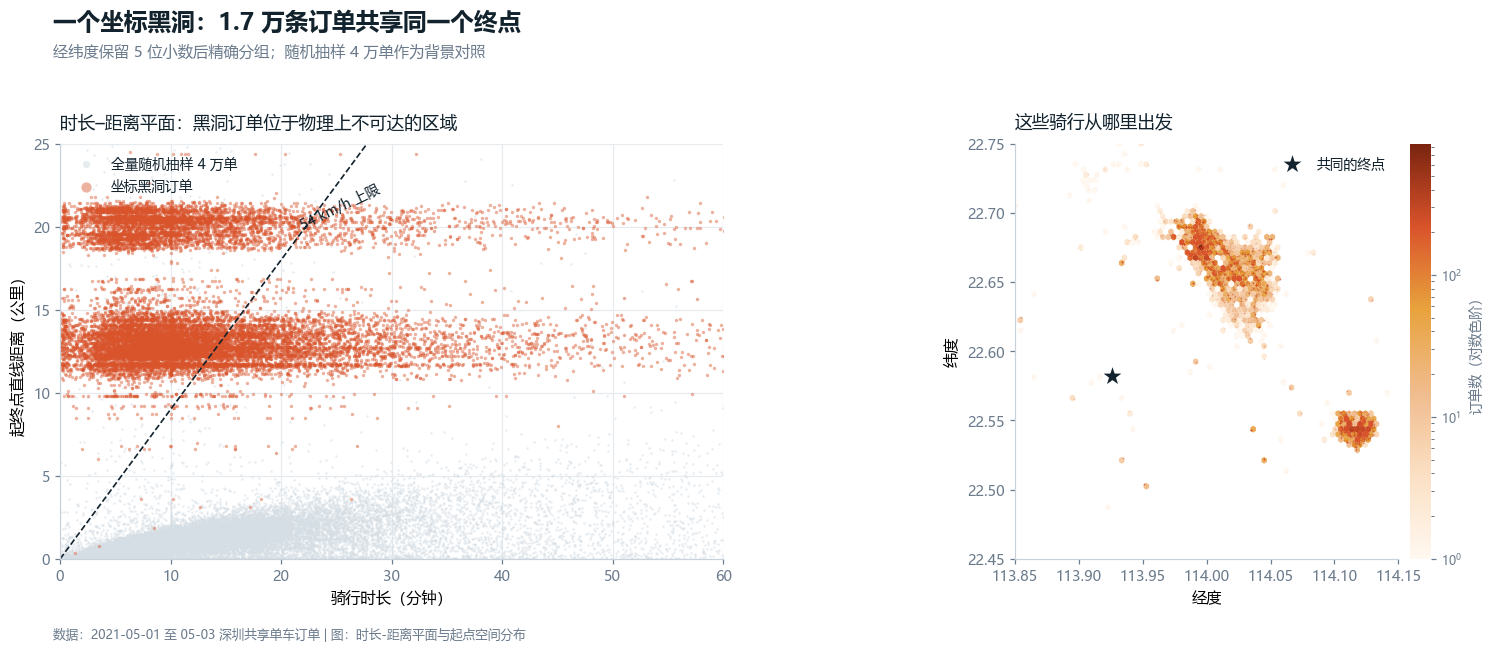

In [8]:
rng = np.random.default_rng(42)
sample = df.iloc[rng.choice(len(df), 40_000, replace=False)]

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.9),
                         gridspec_kw={"width_ratios": [1.15, 1]})
fig.subplots_adjust(left=0.06, right=0.98, top=0.78, bottom=0.14, wspace=0.22)

# 左：时长 - 距离平面，对角线是等速线
ax = axes[0]
ax.scatter(sample.duration_s / 60, sample.distance_m / 1000, s=2.5,
           c="#D5DEE4", alpha=0.55, linewidths=0, rasterized=True, label="全量随机抽样 4 万单")
ax.scatter(bh.duration_s / 60, bh.distance_m / 1000, s=5,
           c=C["coral"], alpha=0.45, linewidths=0, rasterized=True, label="坐标黑洞订单")
t = np.linspace(0, 32, 100)
ax.plot(t, 15 * t * 60 / 1000, color=C["ink"], lw=1.1, ls="--")
ax.text(21.5, 15 * 21.5 * 60 / 1000 + 0.5, "54 km/h 上限", fontsize=9, color=C["ink"], rotation=26)
ax.set_xlim(0, 60)
ax.set_ylim(0, 25)
ax.set_xlabel("骑行时长（分钟）")
ax.set_ylabel("起终点直线距离（公里）")
ax.set_title("时长–距离平面：黑洞订单位于物理上不可达的区域", loc="left",
             fontsize=11.5, color=C["ink"], pad=10)
style_ax(ax, "both")
ax.legend(loc="upper left", frameon=False, fontsize=9, markerscale=3)

# 右：黑洞订单的起点分布
ax = axes[1]
hb = ax.hexbin(bh.start_lng, bh.start_lat, gridsize=70, cmap=CMAP_WARM, bins="log", mincnt=1,
               extent=(113.85, 114.15, 22.45, 22.75), linewidths=0)
ax.scatter([black_hole_lng], [black_hole_lat], marker="*", s=260,
           c=C["ink"], edgecolors="white", linewidths=1.2, zorder=5, label="共同的终点")
ax.scatter(bh.start_lng, bh.start_lat, s=1, c=C["coral"], alpha=0.08, linewidths=0, rasterized=True)
ax.set_xlim(113.85, 114.15)
ax.set_ylim(22.45, 22.75)
ax.set_aspect(1 / np.cos(np.radians(22.6)))
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
ax.set_title("这些骑行从哪里出发", loc="left", fontsize=11.5, color=C["ink"], pad=10)
style_ax(ax, None)
ax.legend(loc="upper right", frameon=False, fontsize=9)
cb = fig.colorbar(hb, ax=ax, fraction=0.046, pad=0.02)
cb.set_label("订单数（对数色阶）", fontsize=9, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

fig_header(fig, "一个坐标黑洞：1.7 万条订单共享同一个终点",
           "经纬度保留 5 位小数后精确分组；随机抽样 4 万单作为背景对照")
fig_footer(fig, "数据：2021-05-01 至 05-03 深圳共享单车订单 | 图：时长-距离平面与起点空间分布")
plt.show()

In [9]:
start_group = (df.groupby([start_key.lat, start_key.lng])
                 .agg(订单数=("user_code", "size"), 用户数=("user_code", "nunique")))
end_group = (df.groupby([end_key.lat, end_key.lng])
               .agg(订单数=("user_code", "size"), 用户数=("user_code", "nunique")))

print("【起点】精确坐标 Top 6")
display(start_group.sort_values("订单数", ascending=False).head(6))

start_fence = start_group[start_group["用户数"] > 100]
end_fence = end_group[end_group["用户数"] > 100]
print(f"被 100 位以上不同用户共享的坐标：")
print(f"  起点侧 {len(start_fence):,} 个，覆盖 {start_fence['订单数'].sum():,} 单"
      f"（{start_fence['订单数'].sum()/len(df):.2%}）")
print(f"  终点侧 {len(end_fence):,} 个，覆盖 {end_fence['订单数'].sum():,} 单"
      f"（{end_fence['订单数'].sum()/len(df):.2%}）")

【起点】精确坐标 Top 6


,,订单数,用户数
lat,lng,,
22.60,113.85,2971,2562
22.58,113.86,2016,1827
22.60,113.85,1800,1648
22.56,113.89,1724,1522
22.57,113.87,1686,1503
22.70,113.82,1512,1436


被 100 位以上不同用户共享的坐标：
  起点侧 1,194 个，覆盖 293,492 单（8.72%）
  终点侧 3 个，覆盖 25,860 单（0.77%）


### 3.2 如何解读这个黑洞

三条证据指向同一个结论：这不是真实出行，而是**定位或字段写入环节的系统性错位**。

1. **物理上不可能**。这批订单的中位距离约 13.5 km，中位时长约 10.6 分钟，隐含速度 70 km/h 以上。共享单车不可能达到这个速度，连电动自行车也做不到。
2. **空间高度集中**。起点集中在龙华一侧，终点则精确到同一个 1 米见方的坐标，说明终点不是测量得到的，而是被"赋值"的。
3. **数量级异常**。1.6 万余条订单、1.2 万个独立用户共享同一终点坐标。相比之下，起点侧的"电子围栏停车点"虽然也会让同一坐标被上百位用户使用（覆盖约 8% 的订单），但终点侧几乎没有这种现象，说明两端的坐标生成逻辑不同。

这类记录不能被"均值填充"或"删除异常值"草率处理掉，因为它们的起点其实是真实的。但在缺少车辆 ID 和站点 ID 的情况下，我们无法还原真实的终点，只能在运动学层面把它们剔除。**本文后续所有分析均不包含这批记录。**

> 实践建议：如果这份数据用于生产，应该向上游核查关锁坐标的写入逻辑，尤其是跨区骑行订单。一个 1.7 万单的固定终点足以让任何基于 OD 的分析产生偏差。

## 4. 清洗流程

清洗规则按"从强到弱"的顺序执行，每一步都记录剩余量，最终保留 **94.8%** 的订单。规则的设计原则是：**只删除物理上不可能、或无法用于时空分析的记录，不删除"看起来不典型"的真实行为。**

| 规则 | 阈值 | 依据 |
|---|---|---|
| 去重 | 全字段相同 | 重复导出或重试写入 |
| 坐标有效 | 落在深圳外接矩形内 | 越界点无法参与空间分析 |
| 时长 | 60 s ≤ t ≤ 3 h | 低于 1 分钟多为开锁即关；超过 3 小时属于车辆丢失或未正常关锁 |
| 距离 | 50 m ≤ d ≤ 20 km | 低于 50 米是原地挪车；超过 20 公里超出单车合理使用范围 |
| 速度 | v ≤ 15 m/s（54 km/h） | 人力骑行的物理上限，用于拦截定位错位 |

阈值不是拍脑袋定的：时长和距离的 P1 / P99 分位、速度分布的右尾（见上一节）都支持这个切点。3 小时的保留上限相对宽松，是为了不误伤真实的长时间骑行（例如骑行游览）。

In [10]:
def clean_orders(data):
    """按顺序执行清洗规则，并记录每一步的剩余量。"""
    lat_min, lat_max, lng_min, lng_max = SHENZHEN_BBOX
    log = []
    d = data

    log.append(("原始数据", len(d)))
    d = d.drop_duplicates()
    log.append(("去重", len(d)))
    d = d[d.start_lat.between(lat_min, lat_max) & d.start_lng.between(lng_min, lng_max)
          & d.end_lat.between(lat_min, lat_max) & d.end_lng.between(lng_min, lng_max)]
    log.append(("坐标落在深圳范围内", len(d)))
    d = d[d.duration_s.between(60, 3 * 3600)]
    log.append(("时长 1 分钟 – 3 小时", len(d)))
    d = d[d.distance_m.between(50, 20_000)]
    log.append(("距离 50 米 – 20 公里", len(d)))
    d = d[d.speed_ms <= 15]
    log.append(("速度 ≤ 54 km/h", len(d)))
    return d.copy(), pd.DataFrame(log, columns=["步骤", "剩余记录"])


dfc, clean_log = clean_orders(df)
clean_log["剔除"] = (-clean_log["剩余记录"].diff()).fillna(0).astype(int)
clean_log["保留率"] = clean_log["剩余记录"] / clean_log.loc[0, "剩余记录"]
display(clean_log.style.format({"剩余记录": "{:,}", "剔除": "{:,}", "保留率": "{:.2%}"}))

print(f"清洗后 {len(dfc):,} 条（{len(dfc)/len(df):.2%}），"
      f"唯一用户 {dfc.user_code.nunique():,}，"
      f"累计里程 {dfc.distance_m.sum()/1e3:,.0f} km")

,步骤,剩余记录,剔除,保留率
0,原始数据,"3,364,413",0,100.00%
1,去重,"3,359,773","4,640",99.86%
2,坐标落在深圳范围内,"3,356,934","2,839",99.78%
3,时长 1 分钟 – 3 小时,"3,306,237","50,697",98.27%
4,距离 50 米 – 20 公里,"3,217,751","88,486",95.64%
5,速度 ≤ 54 km/h,"3,189,049","28,702",94.79%


清洗后 3,189,049 条（94.79%），唯一用户 1,206,439，累计里程 3,908,281 km


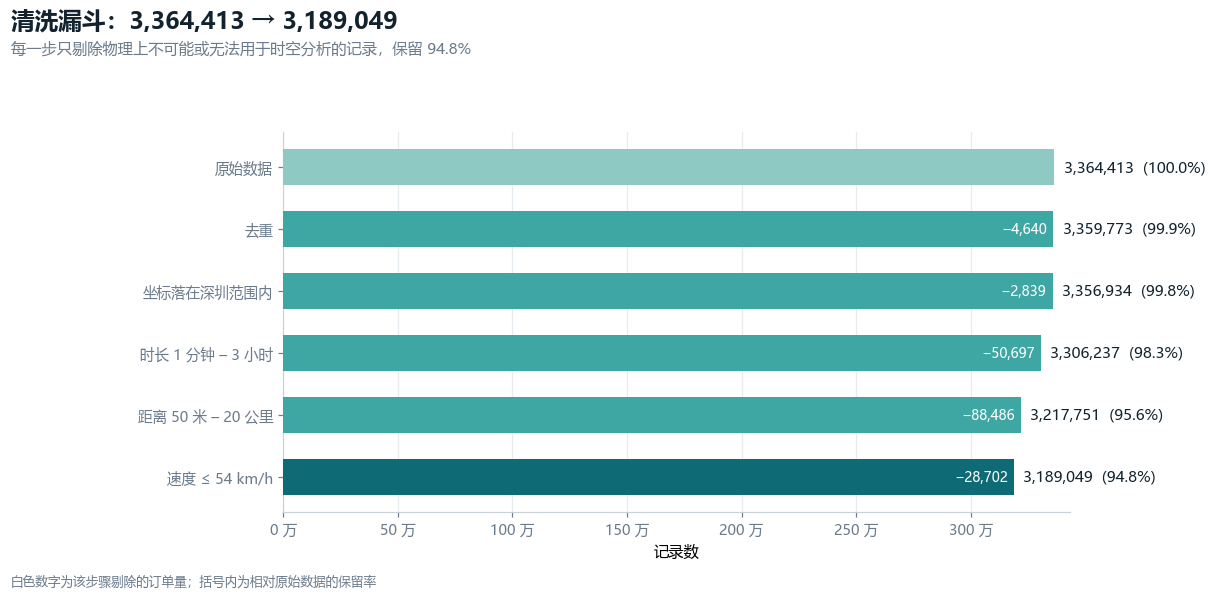

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.4))
fig.subplots_adjust(left=0.28, right=0.93, top=0.78, bottom=0.14)

steps = clean_log["步骤"].tolist()
remain = clean_log["剩余记录"].values
ypos = np.arange(len(steps))[::-1]
colors = [C["teal3"]] + [C["teal2"]] * (len(steps) - 2) + [C["teal"]]

ax.barh(ypos, remain, height=0.58, color=colors, edgecolor="none", zorder=3)
for y, v in zip(ypos, remain):
    ax.text(v + remain[0] * 0.012, y, f"{v:,}  ({v/remain[0]:.1%})",
            va="center", fontsize=10, color=C["ink"])

# 剔除量画在条形内部，避免与右侧数字重叠
for i in range(1, len(steps)):
    dropped = remain[i - 1] - remain[i]
    if dropped > 0:
        ax.text(remain[i] - remain[0] * 0.008, ypos[i], f"−{dropped:,}",
                va="center", ha="right", fontsize=9, color="white")

ax.set_yticks(ypos)
ax.set_yticklabels(steps, fontsize=10.5, color=C["ink"])
ax.set_xlim(0, remain[0] * 1.02)
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{x/1e4:.0f} 万"))
ax.set_xlabel("记录数")
style_ax(ax, "x")
ax.grid(axis="x", color=C["grid"], lw=0.8)
ax.grid(axis="y", visible=False)

fig_header(fig, "清洗漏斗：3,364,413 → 3,189,049",
           "每一步只剔除物理上不可能或无法用于时空分析的记录，保留 94.8%")
fig_footer(fig, "白色数字为该步骤剔除的订单量；括号内为相对原始数据的保留率")
plt.show()

## 5. 特征工程

所有后续分析都建立在同一张"增强表"上。新增字段分四类：

| 类别 | 字段 | 说明 |
|---|---|---|
| 时间 | `date` `hour` `minute` | 开锁时刻；跨日订单以开锁时间归属日期 |
| 运动学 | `duration_min` `speed_kmh` | 由基础字段换算 |
| 空间 | `sy` `sx` `ey` `ex` | 0.01° 网格（约 1.1 km × 1.0 km）的行列号 |
| 空间 | `cell_start` `cell_end` | 网格整数编码 `sy × 100000 + sx`，用于高速分组 |
| 语义 | `area_start` | 最近片区名称，用于把网格翻译成地名 |

网格边长选 0.01° 是一个折中：再细会因 GPS 抖动导致同一停车点被拆成多个格；再粗会抹平 CBD 内部的结构。0.01° 在深圳纬度上对应约 **1.1 km × 1.0 km**，接近一个街区组团的尺度。

片区名称由最近的片区中心点近似映射（精度约 ±1–2 km），只用于可读性，不参与计算。

In [12]:
def add_features(d):
    """在清洗后的订单上构造时间、空间与语义特征。"""
    d = d.copy()
    # 时间
    d["date"] = d.start_time.dt.normalize()
    d["date_str"] = d.start_time.dt.strftime("%m-%d")
    d["hour"] = d.start_time.dt.hour.astype("int8")
    d["minute"] = d.start_time.dt.minute.astype("int16")
    d["duration_min"] = d.duration_s / 60
    d["speed_kmh"] = d.speed_ms * 3.6
    # 网格（0.01°）
    d["sy"] = np.floor(d.start_lat / GRID).astype("int16")
    d["sx"] = np.floor(d.start_lng / GRID).astype("int16")
    d["ey"] = np.floor(d.end_lat / GRID).astype("int16")
    d["ex"] = np.floor(d.end_lng / GRID).astype("int16")
    d["cell_start"] = d.sy.astype("int32") * 100_000 + d.sx
    d["cell_end"] = d.ey.astype("int32") * 100_000 + d.ex
    # 片区语义：按网格中心点映射，避免对 300 万行逐点计算
    geo_s = d.groupby("cell_start").agg(lat=("start_lat", "mean"), lng=("start_lng", "mean"))
    geo_e = d.groupby("cell_end").agg(lat=("end_lat", "mean"), lng=("end_lng", "mean"))
    geo_s["area"], _ = area_label(geo_s.lat.values, geo_s.lng.values)
    geo_e["area"], _ = area_label(geo_e.lat.values, geo_e.lng.values)
    d["area_start"] = d.cell_start.map(geo_s["area"])
    d["area_end"] = d.cell_end.map(geo_e["area"])
    return d


dfc = add_features(dfc)
print(f"特征表：{dfc.shape[0]:,} 行 × {dfc.shape[1]} 列")
print(f"占用网格数（起点）：{dfc.cell_start.nunique():,}")
display(dfc[["start_time", "duration_min", "distance_m", "speed_kmh",
             "sy", "sx", "cell_start", "area_start"]].head(5))

特征表：3,189,049 行 × 24 列
占用网格数（起点）：1,144


,start_time,duration_min,distance_m,speed_kmh,sy,sx,cell_start,area_start
1,2021-05-01,9.35,974.40,6.25,2262,11406,226211406,龙岗·坂田
2,2021-05-01,9.87,412.91,2.51,2271,11380,227111380,宝安·沙井
3,2021-05-01,9.87,412.91,2.51,2271,11380,227111380,宝安·沙井
4,2021-05-01,6.85,906.47,7.94,2256,11390,225611390,宝安·新安
5,2021-05-01,6.68,481.55,4.32,2253,11409,225311409,福田·华强北


In [13]:
daily = (dfc.groupby("date_str")
            .agg(订单数=("user_code", "size"),
                 活跃用户=("user_code", "nunique"),
                 中位距离_米=("distance_m", "median"),
                 中位时长_分钟=("duration_min", "median"),
                 中位速度_kmh=("speed_kmh", "median"))
            .reset_index().rename(columns={"date_str": "日期"}))
daily["订单占比"] = daily["订单数"] / daily["订单数"].sum()
display(daily.style.format({"订单数": "{:,}", "活跃用户": "{:,}", "订单占比": "{:.1%}",
                            "中位距离_米": "{:,.0f}", "中位时长_分钟": "{:.1f}",
                            "中位速度_kmh": "{:.1f}"}))

print(f"三天合计：{len(dfc):,} 单 | {dfc.user_code.nunique():,} 位用户 | "
      f"{dfc.distance_m.sum()/1e3:,.0f} km | 人均 {len(dfc)/dfc.user_code.nunique():.2f} 单")

,日期,订单数,活跃用户,中位距离_米,中位时长_分钟,中位速度_kmh,订单占比
0,05-01,"1,278,950","679,916",906,9.8,6.1,40.1%
1,05-02,"860,549","487,964",879,9.0,6.4,27.0%
2,05-03,"1,049,550","563,549",910,9.7,6.2,32.9%


三天合计：3,189,049 单 | 1,206,439 位用户 | 3,908,281 km | 人均 2.64 单


## 6. 时间维度：三天三套剧本

把三天的小时曲线叠在一起，会看到一个反直觉的结果：**同一个假期、同一座城市、同一批用户，三天的形状完全不同。**

- **5 月 1 日**：零点这一小时仍有 **2.27 万单**，是三天里最高的，说明假期的第一夜属于夜宵、聚会和跨区返程。白天从 8 点开始爬升，18 点达到全假期最高点 **9.65 万单/小时**，夜间衰减很慢。
- **5 月 2 日**：凌晨与 5 月 1 日基本持平（0 点 2.16 万），上午略低（8 点 6.9 万，5 月 1 日为 7.5 万），但 **13–15 点反而更高**，15 点达到 7.0 万，是这一天的峰值。16 点之后突然塌陷，晚高峰几乎消失。
- **5 月 3 日**：凌晨最安静（0 点只有 **4,714 单**，不到 5 月 1 日的四分之一），白天平稳，17–19 点出现一个更"收拢"的晚高峰（18 点 **8.95 万单**），像是假期结束前的最后一次集中出行。

5 月 1 日和 5 月 3 日的峰值都落在 17–19 点，说明假期的出行主引擎是**傍晚的休闲与消费**，而不是工作日的早晚通勤双峰。5 月 2 日是一个例外：它的峰值提前到了 15 点，因为 16 点之后的那场扰动把晚高峰直接抹掉了。接下来我们把这一天单独拆开看。

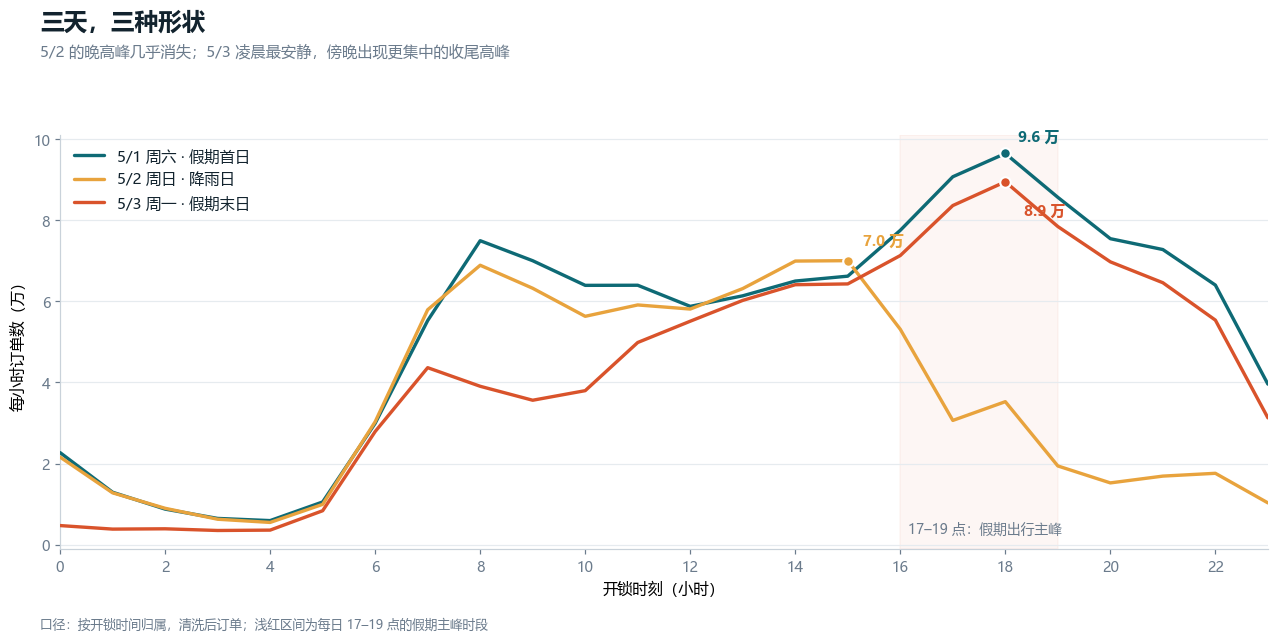

In [14]:
hourly = (dfc.groupby(["date_str", "hour"]).size()
             .unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
day_labels = {"05-01": "5/1 周六 · 假期首日", "05-02": "5/2 周日 · 降雨日", "05-03": "5/3 周一 · 假期末日"}
day_colors = {"05-01": C["teal"], "05-02": C["gold"], "05-03": C["coral"]}

fig, ax = plt.subplots(figsize=(12.2, 5.8))
fig.subplots_adjust(left=0.07, right=0.97, top=0.79, bottom=0.14)

peak_offsets = {"05-01": (8, 8), "05-02": (10, 10), "05-03": (12, -22)}
for d in hourly.index:
    ax.plot(hourly.columns, hourly.loc[d] / 1e4, lw=2.2, color=day_colors[d],
            label=day_labels[d], zorder=3, solid_capstyle="round")
    peak_h = hourly.loc[d].idxmax()
    ax.scatter([peak_h], [hourly.loc[d, peak_h] / 1e4], s=48, color=day_colors[d],
               edgecolor="white", linewidth=1.4, zorder=5)
    ax.annotate(f"{hourly.loc[d, peak_h]/1e4:.1f} 万",
                (peak_h, hourly.loc[d, peak_h] / 1e4),
                xytext=peak_offsets.get(d, (8, 8)), textcoords="offset points",
                fontsize=9.5, color=day_colors[d], fontweight="bold")

ax.axvspan(16, 19, color=C["coral"], alpha=0.05, zorder=0)
ax.text(16.15, ax.get_ylim()[1] * 0.03, "17–19 点：假期出行主峰", fontsize=9, color=C["muted"])

ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("开锁时刻（小时）")
ax.set_ylabel("每小时订单数（万）")
style_ax(ax, "y")
ax.legend(loc="upper left", frameon=False, fontsize=10, ncol=1)

fig_header(fig, "三天，三种形状",
           "5/2 的晚高峰几乎消失；5/3 凌晨最安静，傍晚出现更集中的收尾高峰")
fig_footer(fig, "口径：按开锁时间归属，清洗后订单；浅红区间为每日 17–19 点的假期主峰时段")
plt.show()

### 6.1 5 月 2 日：一场午后扰动

把粒度从小时切到 10 分钟，5 月 2 日的事件就非常清楚了：

- 15:50 之前，骑行量稳定在每 10 分钟 1.1–1.2 万单；
- **16:10 开始下滑，16:40–17:10 出现陡降**，17:10 触底 4,539 单，较 15:50 下降 **60%**；
- 之后只有微弱反弹，整个晚上都维持在低位（22 点 1.76 万单，而 5 月 1 日同期是 6.4 万单）。

更关键的是**空间上的同步性**：如果是一次局部活动（演唱会散场、封路），下跌应该集中在个别片区；而实际是有足够样本的 35 个片区里，33 个在同一时间窗口下跌，且跌幅相近。这种"全城同时、快速见底、持续数小时"的形态，最合理的解释是**短时强降雨**——雨来得快，骑行者立刻放弃骑行；雨停后需求也没有完全恢复，因为出行计划已经被打乱。

这是一次天然的对照实验：同一座城市、同一批用户、相邻的两天，唯一的系统性差异是天气。它直接说明了一件事：**共享单车的需求对天气高度敏感，任何节假日的运力安排都必须把天气作为一阶变量，而不是备注。**

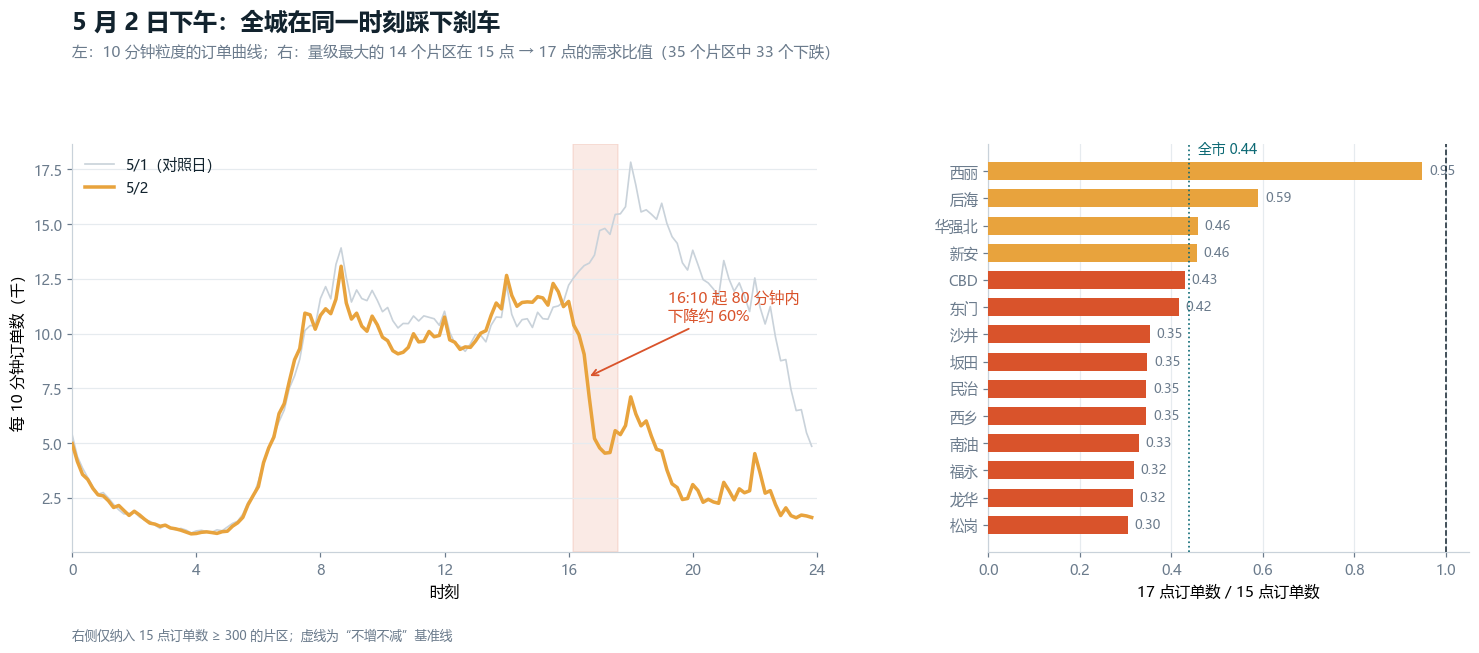

5/2 全市 17 点 / 15 点订单比：0.438
纳入统计的片区数：35，其中比值小于 1 的片区：33
展示片区的比值范围：0.30 – 0.95


In [15]:
def ten_min_series(day):
    s = dfc.loc[dfc.date_str == day, "start_time"]
    s = s.dt.floor("10min").value_counts().sort_index()
    x = (s.index - s.index.normalize()).total_seconds() / 3600
    return x, s.values


x1, y1 = ten_min_series("05-01")
x2, y2 = ten_min_series("05-02")

# 片区级的同步性：比较 15 点与 17 点的小时订单量
d2 = dfc[dfc.date_str == "05-02"]
ratio = (d2[d2.hour.isin([14, 15, 16, 17, 18])]
         .groupby(["area_start", "hour"]).size().unstack(fill_value=0))
ratio = ratio[ratio[15] >= 300]
ratio["ratio"] = ratio[17] / ratio[15]
overall_ratio = ratio[17].sum() / ratio[15].sum()
n_areas, n_down = len(ratio), int((ratio["ratio"] < 1).sum())
ratio = ratio.sort_values(15, ascending=False).head(14).sort_values("ratio")

fig, axes = plt.subplots(1, 2, figsize=(13.8, 5.9),
                         gridspec_kw={"width_ratios": [1.55, 1]})
fig.subplots_adjust(left=0.055, right=0.975, top=0.78, bottom=0.15, wspace=0.28)

# 左：10 分钟粒度
ax = axes[0]
ax.plot(x1, y1 / 1e3, lw=1.1, color=C["line"], label="5/1（对照日）", zorder=2)
ax.plot(x2, y2 / 1e3, lw=2.3, color=C["gold"], label="5/2", zorder=3)
ax.axvspan(16.15, 17.6, color=C["coral"], alpha=0.12, zorder=0)
ax.annotate("16:10 起 80 分钟内\n下降约 60%", xy=(16.6, 8.0), xytext=(19.2, 10.6),
            fontsize=10, color=C["coral"], ha="left",
            arrowprops=dict(arrowstyle="->", color=C["coral"], lw=1.2))
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 4))
ax.set_xlabel("时刻")
ax.set_ylabel("每 10 分钟订单数（千）")
style_ax(ax, "y")
ax.legend(loc="upper left", frameon=False, fontsize=9.5)

# 右：各片区 17 点 / 15 点的比值
ax = axes[1]
vals = ratio["ratio"].values
ylabels = [s.split("·")[-1] for s in ratio.index]
colors = [C["coral"] if v < overall_ratio else C["gold"] for v in vals]
ax.barh(np.arange(len(vals)), vals, color=colors, height=0.66, zorder=3)
ax.axvline(1.0, color=C["ink"], lw=1, ls="--", zorder=4)
ax.axvline(overall_ratio, color=C["teal"], lw=1.1, ls=":", zorder=4)
ax.text(overall_ratio + 0.02, len(vals) - 0.35, f"全市 {overall_ratio:.2f}",
        fontsize=9, color=C["teal"])
for i, v in enumerate(vals):
    ax.text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=8.6, color=C["muted"])
ax.set_yticks(np.arange(len(vals)))
ax.set_yticklabels(ylabels, fontsize=8.8)
ax.set_xlim(0, 1.05)
ax.set_xlabel("17 点订单数 / 15 点订单数")
style_ax(ax, "x")
ax.grid(axis="x", color=C["grid"], lw=0.8)

fig_header(fig, "5 月 2 日下午：全城在同一时刻踩下刹车",
           f"左：10 分钟粒度的订单曲线；右：量级最大的 14 个片区在 15 点 → 17 点的需求比值"
           f"（{n_areas} 个片区中 {n_down} 个下跌）")
fig_footer(fig, "右侧仅纳入 15 点订单数 ≥ 300 的片区；虚线为“不增不减”基准线")
plt.show()

print(f"5/2 全市 17 点 / 15 点订单比：{overall_ratio:.3f}")
print(f"纳入统计的片区数：{n_areas}，其中比值小于 1 的片区：{n_down}")
print(f"展示片区的比值范围：{ratio['ratio'].min():.2f} – {ratio['ratio'].max():.2f}")

## 7. 空间维度：城市的热力骨架

把 318.9 万个起点画在地图上，第一眼看到的结构可能与直觉不同：**最亮、最连片的区域不是福田 CBD，而是宝安—龙华一带的居住与产业混合区**。这里的订单密度高、分布连续，说明共享单车在这些片区承担了相当重的日常短途出行。

福田—罗湖走廊是第二层结构：范围更窄，但亮区的浓度极高，东门、华强北、车公庙一带形成了几个"针尖"级的热点。南山则沿科技园—后海—白石洲呈现一条带状分布。东部（龙岗、坪山、大鹏）密度明显下降，只有少数几个组团。

这种"西强东弱、中心极密"的格局，与深圳的人口和产业分布基本一致，但也提示了一件事：**共享单车的需求并不只由 CBD 驱动**。产业园区、城中村、大型居住区同样是高频场景，甚至在绝对量上更大。这对运营的含义是，投放策略不能只盯着写字楼。

下面先用六边形热力图看整体，再拆到四个时段看相对强度的变化。

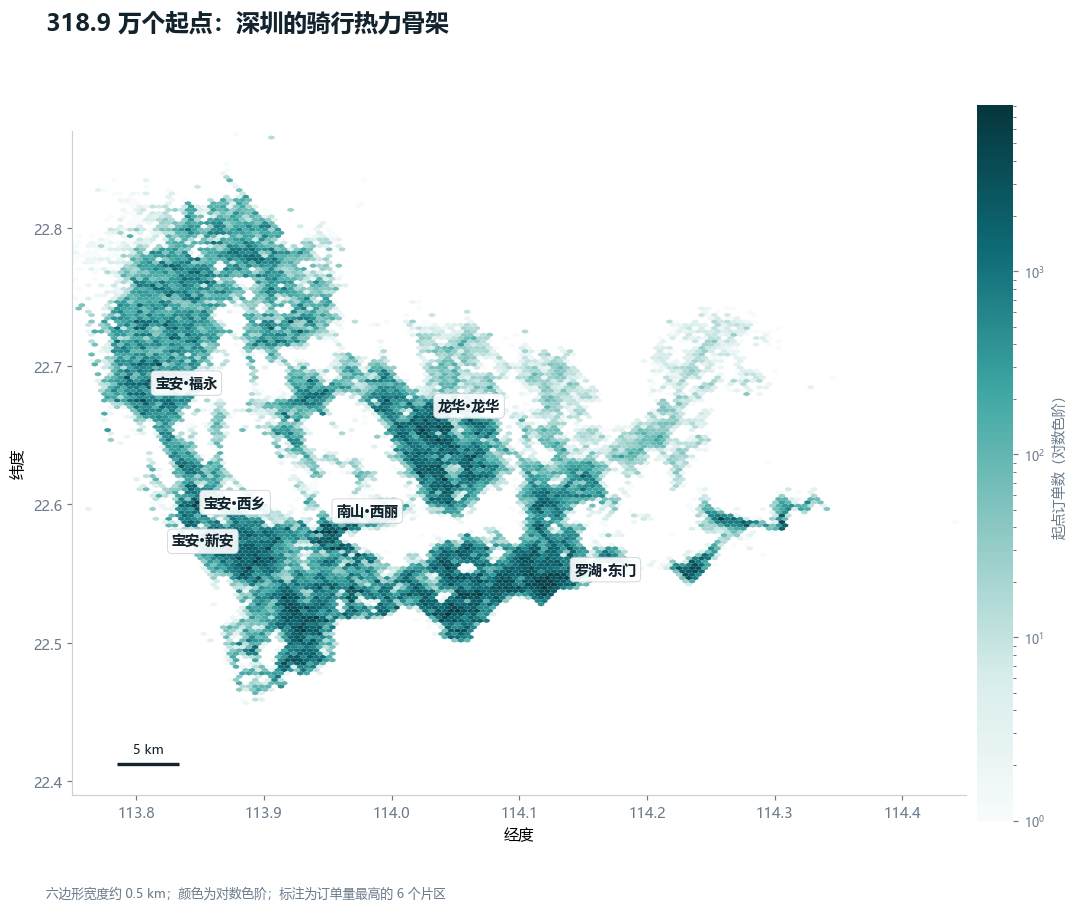

In [16]:
lng0, lng1, lat0, lat1 = 113.75, 114.63, 22.39, 22.87

fig, ax = plt.subplots(figsize=(9.4, 8.4))
fig.subplots_adjust(left=0.08, right=0.99, top=0.90, bottom=0.07)

hb = ax.hexbin(dfc.start_lng, dfc.start_lat, gridsize=175, cmap=CMAP_TEAL, bins="log",
               mincnt=1, extent=(lng0, lng1, lat0, lat1), linewidths=0.0)
ax.set_xlim(lng0, 114.45)      # 东部无服务数据，裁掉空白
ax.set_ylim(lat0, lat1)
ax.set_aspect(1 / np.cos(np.radians(22.6)))
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
style_ax(ax, None)

# 标注订单量最高的片区：用其实际质心，避免文字落在空地上
area_geo = (dfc.groupby("area_start")
            .agg(lat=("start_lat", "mean"), lng=("start_lng", "mean"),
                 n=("user_code", "size"))
            .sort_values("n", ascending=False))
label_offset = {
    "罗湖·东门": (0.040, 0.004), "福田·上沙": (-0.035, -0.022),
    "福田·华强北": (0.038, 0.016), "福田·CBD": (0.015, -0.026),
    "南山·南油": (-0.045, -0.012), "龙华·龙华": (0.035, 0.012),
    "南山·后海": (0.030, -0.018), "宝安·新安": (-0.040, 0.008),
}
for name, row in area_geo.head(6).iterrows():
    dx, dy = label_offset.get(name, (0.02, 0.014))
    ax.text(row.lng + dx, row.lat + dy, name, fontsize=9.2, color=C["ink"], fontweight="bold",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=C["line"], lw=0.6, alpha=0.9))

# 比例尺（5 km）
km5 = 5 / (111.0 * np.cos(np.radians(22.6)))
x0, y0 = lng0 + 0.035, lat0 + 0.022
ax.plot([x0, x0 + km5], [y0, y0], color=C["ink"], lw=2.2, solid_capstyle="butt", zorder=7)
ax.text(x0 + km5 / 2, y0 + 0.008, "5 km", ha="center", fontsize=8.5, color=C["ink"])

cb = fig.colorbar(hb, ax=ax, fraction=0.038, pad=0.012)
cb.set_label("起点订单数（对数色阶）", fontsize=9, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

fig_header(fig, "318.9 万个起点：深圳的骑行热力骨架", None, y=0.975)
fig_footer(fig, "六边形宽度约 0.5 km；颜色为对数色阶；标注为订单量最高的 6 个片区")
plt.show()

In [17]:
cell_stats = (dfc.groupby(["cell_start", "area_start"])
                 .agg(订单数=("user_code", "size"),
                      用户数=("user_code", "nunique"),
                      中位距离_米=("distance_m", "median"),
                      中位时长_分钟=("duration_min", "median"))
                 .reset_index()
                 .sort_values("订单数", ascending=False)
                 .head(15))
cell_stats["网格纬度"] = (cell_stats.cell_start // 100_000 + 0.5) * GRID
cell_stats["网格经度"] = (cell_stats.cell_start % 100_000 + 0.5) * GRID
cell_stats["订单占比"] = cell_stats["订单数"] / len(dfc)

display(cell_stats[["area_start", "网格纬度", "网格经度", "订单数", "用户数",
                    "中位距离_米", "中位时长_分钟", "订单占比"]]
        .rename(columns={"area_start": "片区"})
        .style.format({"订单数": "{:,}", "用户数": "{:,}", "订单占比": "{:.2%}",
                       "中位距离_米": "{:,.0f}", "中位时长_分钟": "{:.1f}",
                       "网格纬度": "{:.3f}", "网格经度": "{:.3f}"})
        .background_gradient(subset=["订单数"], cmap="Blues"))

print(cell_stats[["area_start", "订单数", "中位距离_米"]].head(10).to_string(index=False))

,片区,网格纬度,网格经度,订单数,用户数,中位距离_米,中位时长_分钟,订单占比
147,罗湖·东门,22.545,114.125,"42,672","21,920",676,7.8,1.34%
146,罗湖·东门,22.545,114.115,"36,042","21,912",717,9.0,1.13%
85,福田·上沙,22.525,114.045,"31,135","17,226",774,8.0,0.98%
590,龙华·龙华,22.655,114.025,"26,638","17,583",908,9.6,0.84%
143,福田·华强北,22.545,114.085,"25,872","15,920",725,8.4,0.81%
112,福田·CBD,22.535,114.065,"25,159","13,537",762,8.1,0.79%
73,南山·南油,22.525,113.925,"23,620","15,893",770,9.0,0.74%
111,福田·CBD,22.535,114.055,"23,395","14,203","1,026",10.0,0.73%
179,罗湖·人民南,22.555,114.105,"23,291","13,919",774,8.5,0.73%
54,南山·南油,22.515,113.925,"23,049","15,063",863,9.4,0.72%


area_start   订单数   中位距离_米
     罗湖·东门 42672   675.89
     罗湖·东门 36042   716.59
     福田·上沙 31135   774.03
     龙华·龙华 26638   907.63
    福田·华强北 25872   725.15
    福田·CBD 25159   762.14
     南山·南油 23620   769.59
    福田·CBD 23395 1,026.20
    罗湖·人民南 23291   774.19
     南山·南油 23049   862.89


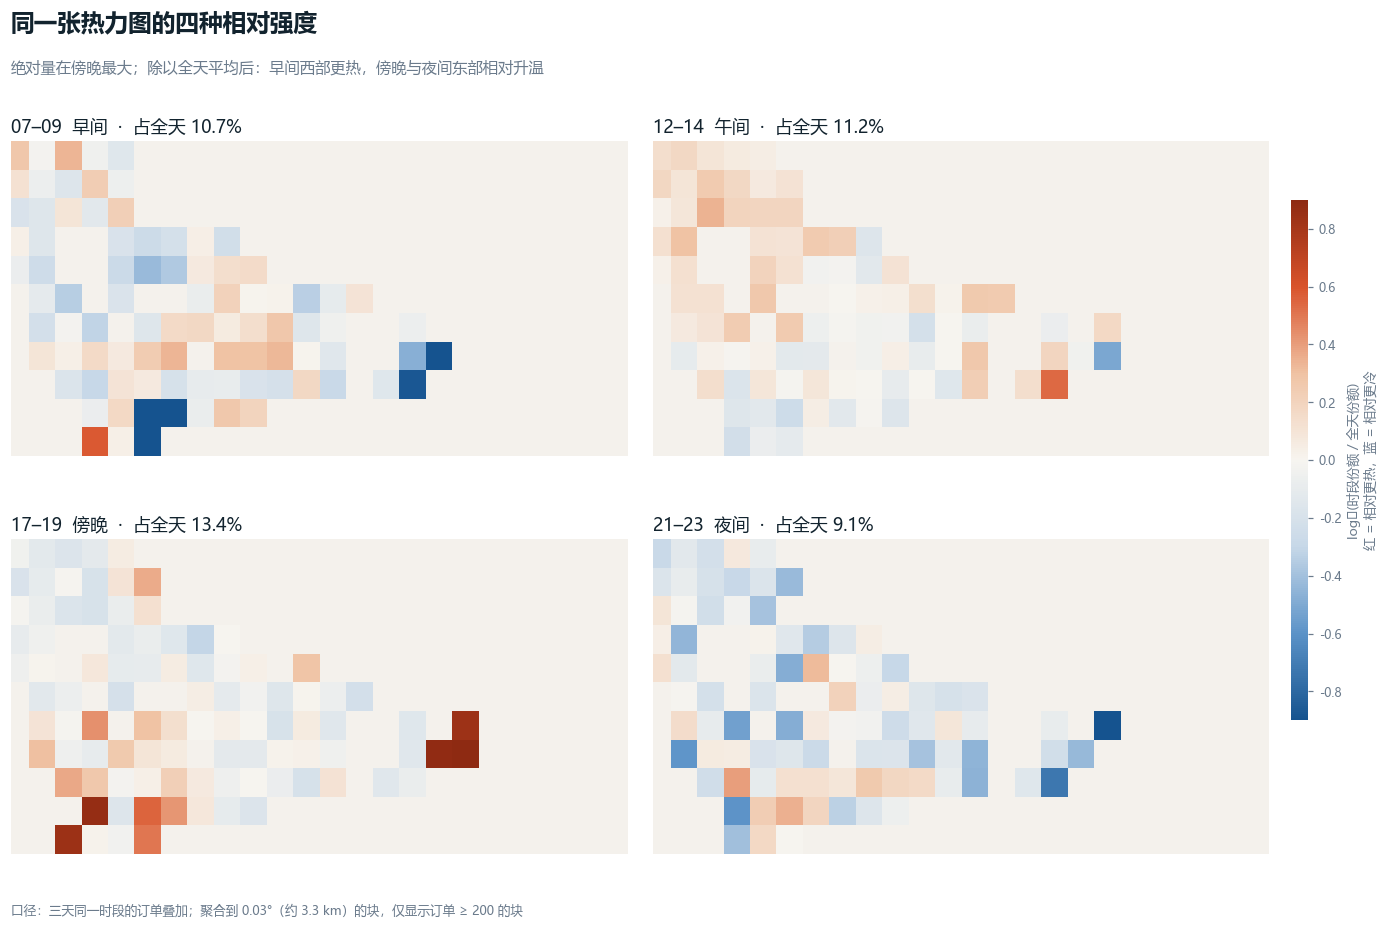

In [18]:
windows = [(7, 9, "07–09  早间"), (12, 14, "12–14  午间"),
           (17, 19, "17–19  傍晚"), (21, 23, "21–23  夜间")]

# 相对强度对单格噪声很敏感，这里聚合到 0.03°（约 3.3 km）的块，并过滤样本过少的块
GS = 0.03
MIN_BLOCK = 200
gx = np.floor(dfc.start_lng / GS).astype(int).values
gy = np.floor(dfc.start_lat / GS).astype(int).values
gx0, gx1, gy0, gy1 = gx.min(), gx.max(), gy.min(), gy.max()
shape = (gy1 - gy0 + 1, gx1 - gx0 + 1)


def block_counts(mask):
    c = np.zeros(shape)
    np.add.at(c, (gy[mask] - gy0, gx[mask] - gx0), 1)
    return c


base = block_counts(np.ones(len(dfc), dtype=bool))
share_all = base / base.sum()

panels = []
for h0, h1, label in windows:
    m = block_counts((dfc.hour.values >= h0) & (dfc.hour.values < h1))
    share_w = np.divide(m, m.sum(), out=np.zeros_like(m), where=m.sum() > 0)
    rel = np.divide(share_w, share_all, out=np.ones_like(m), where=share_all > 0)
    panels.append((label, m.sum() / len(dfc), np.log2(np.clip(rel, 2 ** -0.9, 2 ** 0.9)), m))

fig, axes = plt.subplots(2, 2, figsize=(13.0, 8.6))
fig.subplots_adjust(left=0.03, right=0.91, top=0.86, bottom=0.05, wspace=0.04, hspace=0.08)
extent = (gx0 * GS, (gx1 + 1) * GS, gy0 * GS, (gy1 + 1) * GS)

for ax, (label, day_share, mat, raw) in zip(axes.ravel(), panels):
    im = ax.imshow(np.ma.masked_where(raw < MIN_BLOCK, mat), origin="lower", cmap=CMAP_DIV,
                   norm=TwoSlopeNorm(vcenter=0, vmin=-0.9, vmax=0.9),
                   extent=extent, interpolation="nearest")
    ax.set_xlim(113.80, 114.50)
    ax.set_ylim(22.47, 22.80)
    ax.set_aspect(1 / np.cos(np.radians(22.6)))
    ax.set_title(f"{label}  ·  占全天 {day_share:.1%}", loc="left",
                 fontsize=11.5, color=C["ink"], pad=6)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor("#F4F1EC")
    for spine in ax.spines.values():
        spine.set_visible(False)

cax = fig.add_axes([0.925, 0.22, 0.012, 0.55])
cb = fig.colorbar(im, cax=cax)
cb.set_label("log₂(时段份额 / 全天份额)\n红 = 相对更热，蓝 = 相对更冷", fontsize=8.6, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

fig_header(fig, "同一张热力图的四种相对强度",
           "绝对量在傍晚最大；除以全天平均后：早间西部更热，傍晚与夜间东部相对升温",
           x=0.03, y=0.97)
fig_footer(fig, "口径：三天同一时段的订单叠加；聚合到 0.03°（约 3.3 km）的块，仅显示订单 ≥ 200 的块", x=0.03)
plt.show()

## 8. 距离、时长与速度

三个数字勾勒出共享单车的使用画像：**中位距离 900 米、中位时长 9.6 分钟、中位速度 6.2 km/h**。

这不是"骑行"的速度，而是"从开锁到关锁"的全过程速度，包含找车、步行、等红灯、绕行。真实的骑行速度会更高，但从产品视角看，用户感知的正是这个端到端时间。它说明共享单车解决的并不是"骑行"本身，而是 **500 米到 3 公里之间的短途位移**。

距离分布呈现明显的单峰右偏：一半的订单在 1 公里以内，86% 不超过 2 公里，超过 5 公里的订单只占 1.7%。时长分布则更宽，存在一条明显的长尾：少量超过 1 小时的订单，多为骑行游览、临时锁车办事或未正常关锁。

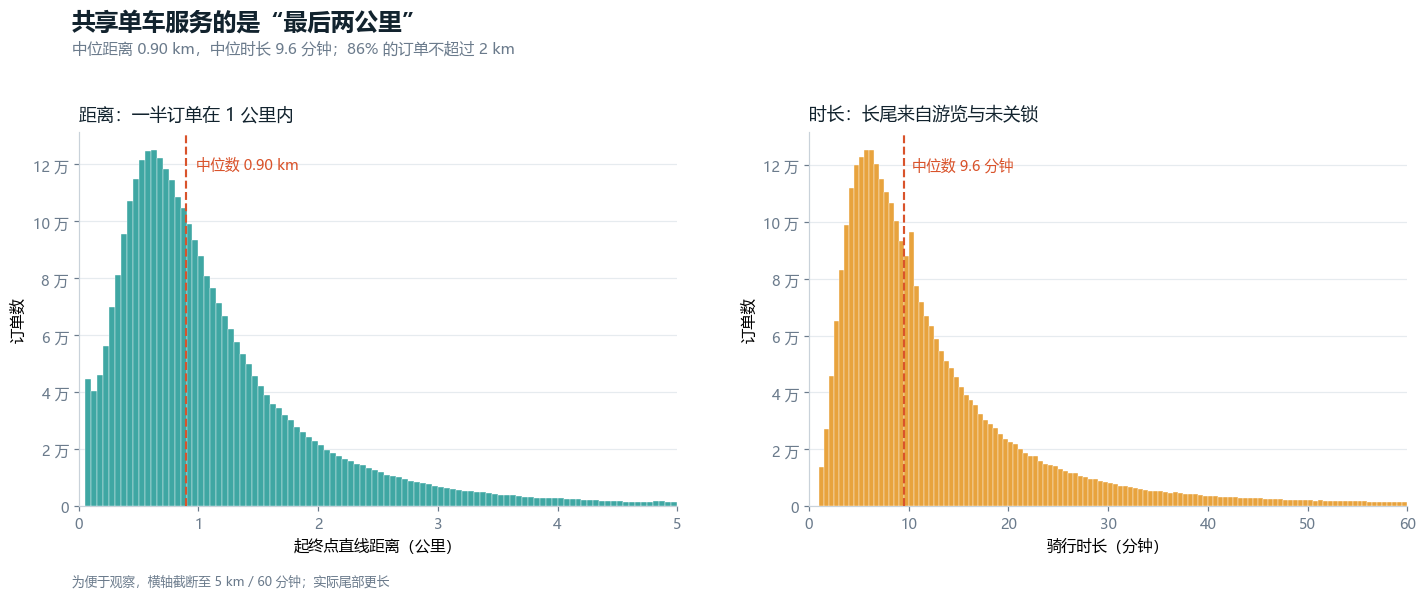

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4))
fig.subplots_adjust(left=0.06, right=0.975, top=0.78, bottom=0.15, wspace=0.22)

# 距离
ax = axes[0]
ax.hist(dfc.distance_m / 1000, bins=np.arange(0, 5.05, 0.05), color=C["teal2"],
        edgecolor="white", lw=0.25, zorder=3)
med_d = dfc.distance_m.median() / 1000
ax.axvline(med_d, color=C["coral"], lw=1.4, ls="--", zorder=4)
ax.text(med_d + 0.08, ax.get_ylim()[1] * 0.9, f"中位数 {med_d:.2f} km",
        fontsize=9.5, color=C["coral"])
ax.set_xlim(0, 5)
ax.set_xlabel("起终点直线距离（公里）")
ax.set_ylabel("订单数")
style_ax(ax, "y")
ax.set_title("距离：一半订单在 1 公里内", loc="left", fontsize=11.5, pad=8)

# 时长
ax = axes[1]
ax.hist(dfc.duration_min, bins=np.arange(0, 60.5, 0.5), color=C["gold"],
        edgecolor="white", lw=0.25, zorder=3)
med_t = dfc.duration_min.median()
ax.axvline(med_t, color=C["coral"], lw=1.4, ls="--", zorder=4)
ax.text(med_t + 0.8, ax.get_ylim()[1] * 0.9, f"中位数 {med_t:.1f} 分钟",
        fontsize=9.5, color=C["coral"])
ax.set_xlim(0, 60)
ax.set_xlabel("骑行时长（分钟）")
ax.set_ylabel("订单数")
style_ax(ax, "y")
ax.set_title("时长：长尾来自游览与未关锁", loc="left", fontsize=11.5, pad=8)

for ax in axes:
    ax.yaxis.set_major_formatter(
        matplotlib.ticker.FuncFormatter(lambda x, _: f"{x/1e4:.0f} 万" if x >= 1e4 else f"{x:.0f}"))

fig_header(fig, "共享单车服务的是“最后两公里”",
           f"中位距离 {med_d:.2f} km，中位时长 {med_t:.1f} 分钟；86% 的订单不超过 2 km")
fig_footer(fig, "为便于观察，横轴截断至 5 km / 60 分钟；实际尾部更长")
plt.show()

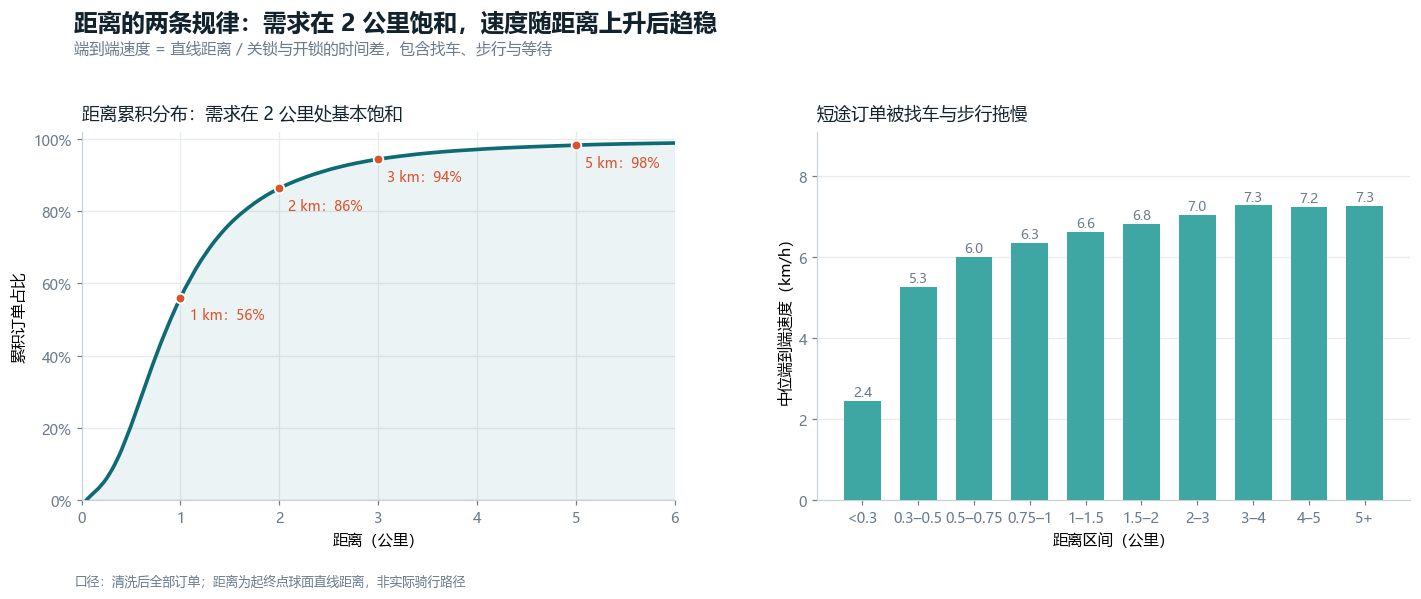

各距离区间的中位端到端速度（km/h）：
dist_bucket
<0.3       2.44
0.3–0.5    5.27
0.5–0.75   6.00
0.75–1     6.35
1–1.5      6.62
1.5–2      6.81
2–3        7.03
3–4        7.27
4–5        7.23
5+         7.25

距离累积占比：
  ≤  1 km：56.05%
  ≤  2 km：86.35%
  ≤  3 km：94.41%
  ≤  5 km：98.30%
  ≤ 10 km：99.57%


In [20]:
d_sorted = np.sort(dfc.distance_m.values)
cdf = np.arange(1, len(d_sorted) + 1) / len(d_sorted)
sel = np.linspace(0, len(d_sorted) - 1, 3000).astype(int)

dist_bins = [0, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 10.0]
dist_labels = ["<0.3", "0.3–0.5", "0.5–0.75", "0.75–1", "1–1.5", "1.5–2", "2–3", "3–4", "4–5", "5+"]
dfc["dist_bucket"] = pd.cut(dfc.distance_m / 1000, dist_bins, labels=dist_labels)
speed_by_dist = dfc.groupby("dist_bucket", observed=True)["speed_kmh"].median()

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4))
fig.subplots_adjust(left=0.06, right=0.975, top=0.78, bottom=0.16, wspace=0.24)

# 左：累积分布
ax = axes[0]
ax.plot(d_sorted[sel] / 1000, cdf[sel], color=C["teal"], lw=2.4, zorder=3)
ax.fill_between(d_sorted[sel] / 1000, 0, cdf[sel], color=C["teal"], alpha=0.08, zorder=2)
for km in (1, 2, 3, 5):
    share = (dfc.distance_m <= km * 1000).mean()
    ax.scatter([km], [share], s=40, color=C["coral"], zorder=5, edgecolor="white", lw=1.2)
    ax.annotate(f"{km} km：{share:.0%}", (km, share), xytext=(6, -14),
                textcoords="offset points", fontsize=9, color=C["coral"])
ax.set_xlim(0, 6)
ax.set_ylim(0, 1.02)
ax.set_xlabel("距离（公里）")
ax.set_ylabel("累积订单占比")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
style_ax(ax, "both")
ax.set_title("距离累积分布：需求在 2 公里处基本饱和", loc="left", fontsize=11.5, pad=8)

# 右：不同距离区间的中位速度
ax = axes[1]
vals = speed_by_dist.values
ax.bar(np.arange(len(vals)), vals, color=C["teal2"], width=0.66, zorder=3)
for i, v in enumerate(vals):
    ax.text(i, v + 0.12, f"{v:.1f}", ha="center", fontsize=8.8, color=C["muted"])
ax.set_xticks(np.arange(len(vals)))
ax.set_xticklabels(dist_labels, fontsize=8.6, rotation=0)
ax.set_ylim(0, vals.max() * 1.25)
ax.set_xlabel("距离区间（公里）")
ax.set_ylabel("中位端到端速度（km/h）")
style_ax(ax, "y")
ax.set_title("短途订单被找车与步行拖慢", loc="left", fontsize=11.5, pad=8)

fig_header(fig, "距离的两条规律：需求在 2 公里饱和，速度随距离上升后趋稳",
           "端到端速度 = 直线距离 / 关锁与开锁的时间差，包含找车、步行与等待")
fig_footer(fig, "口径：清洗后全部订单；距离为起终点球面直线距离，非实际骑行路径")
plt.show()

print("各距离区间的中位端到端速度（km/h）：")
print(speed_by_dist.round(2).to_string())
print("\n距离累积占比：")
for km in (1, 2, 3, 5, 10):
    print(f"  ≤ {km:>2} km：{(dfc.distance_m <= km * 1000).mean():.2%}")

## 9. OD 流向：谁在给谁输血

起点和终点成对出现，构成了一张有向加权图。这一节看三件事：**流向哪里、流多远、流量如何随距离衰减**。

先约定口径：起终点落在同一网格内的订单不参与流向分析。它们占全部订单的 **24.2%**，属于"网格内微移动"，对城市尺度的流动没有信息量。剩下 75.8% 的跨网格订单构成 OD 网络。

从这里开始，一个常见的直觉会被数据推翻。很多人认为共享单车的 OD 是"放射状"的：外围居住区把大量人流送进中心区。但深圳的数据显示，**OD 网络的主体是本地网状结构，而不是跨区放射**：

- 距离超过 3 公里的订单只占全部订单的 **5.6%**，超过 5 公里的只有 1.7%；
- 绝大多数跨网格流量发生在**相邻网格之间**，也就是 1–2 公里的短距离跳跃；
- 真正跨越"骑行社区"的流量只有 4% 左右（下一节会量化）。

这意味着，共享单车在网络意义上更像是一层"城市毛细血管"，而不是"主动脉"。它服务的是街区内部和街区之间的微循环。

跨网格订单：2,417,844（占 75.8%）


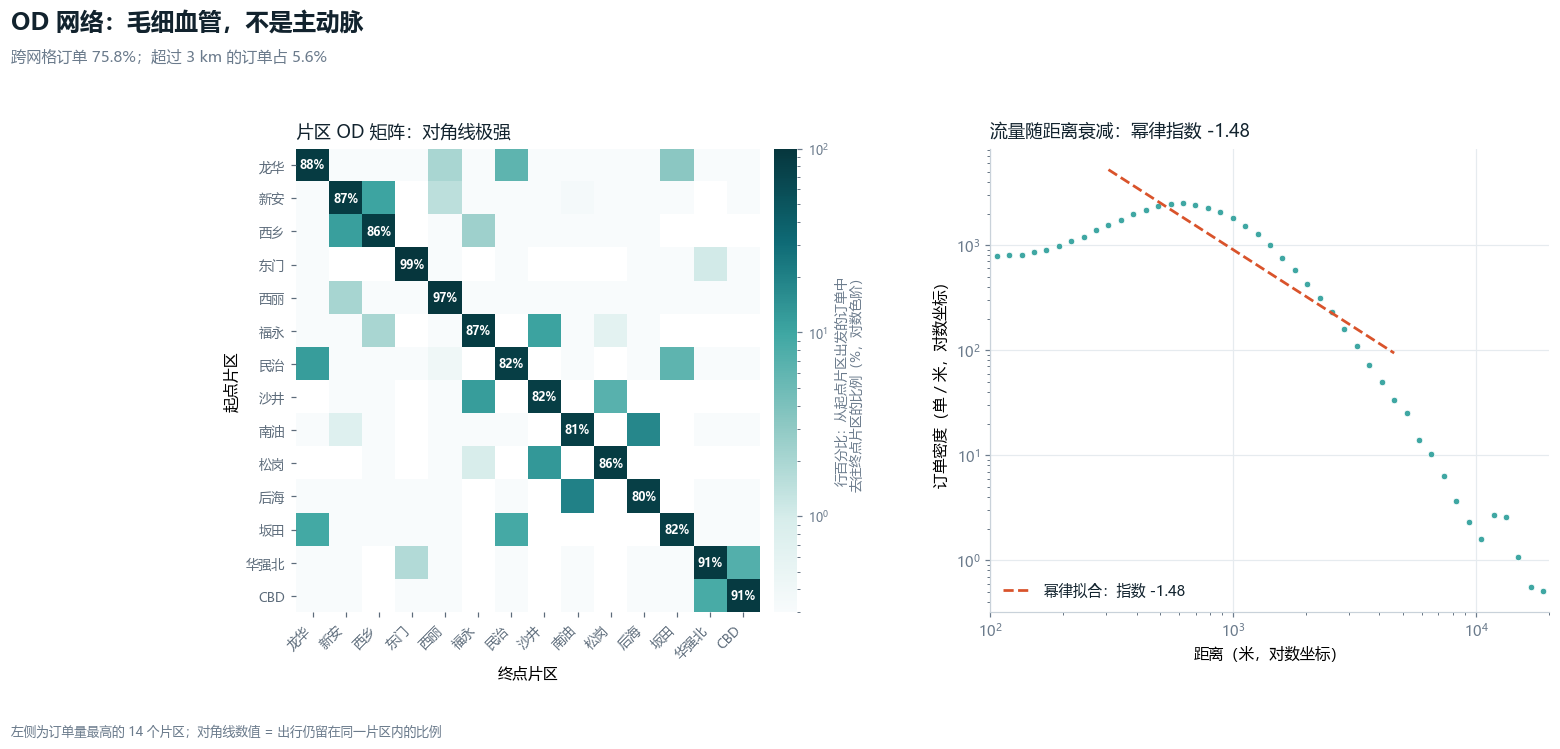

对角（片区内）占比：中位数 86.6%，最低 79.8%，最高 98.7%
幂律拟合指数：-1.485（在 0.3–5 km 区间拟合）


In [21]:
inter = dfc[dfc.cell_start != dfc.cell_end].copy()
print(f"跨网格订单：{len(inter):,}（占 {len(inter)/len(dfc):.1%}）")

# ---- 片区 OD 矩阵（含片区内订单）----
area_flow = dfc.groupby(["area_start", "area_end"]).size().unstack(fill_value=0)
top_area_list = dfc.area_start.value_counts().head(14).index
M = area_flow.reindex(index=top_area_list, columns=top_area_list, fill_value=0)
row_share = M.div(M.sum(axis=1), axis=0) * 100

short = lambda s: s.split("·")[-1]
cmap = CMAP_TEAL.copy()
cmap.set_under("#F8FBFC")

# ---- 距离衰减 ----
edges = np.logspace(np.log10(100), np.log10(20_000), 46)
hist, _ = np.histogram(dfc.distance_m.values, bins=edges)
centers = (edges[:-1] + edges[1:]) / 2
density = hist / np.diff(edges)
mask = (centers >= 300) & (centers <= 5000) & (hist > 0)
slope, intercept = np.polyfit(np.log10(centers[mask]), np.log10(density[mask]), 1)

fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.8),
                         gridspec_kw={"width_ratios": [1.25, 1]})
fig.subplots_adjust(left=0.11, right=0.975, top=0.80, bottom=0.18, wspace=0.30)

# 左：片区 OD 矩阵
ax = axes[0]
im = ax.imshow(row_share.values, cmap=cmap, norm=matplotlib.colors.LogNorm(vmin=0.3, vmax=100),
               interpolation="nearest")
ax.set_xticks(range(len(M)))
ax.set_yticks(range(len(M)))
ax.set_xticklabels([short(s) for s in M.columns], rotation=45, ha="right", fontsize=8.6)
ax.set_yticklabels([short(s) for s in M.index], fontsize=8.6)
ax.set_xlabel("终点片区")
ax.set_ylabel("起点片区")
for i in range(len(M)):
    v = row_share.values[i, i]
    if v >= 1:
        ax.text(i, i, f"{v:.0f}%", ha="center", va="center", fontsize=7.6,
                color="white" if v > 12 else C["ink"], fontweight="bold")
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("片区 OD 矩阵：对角线极强", loc="left", fontsize=11.5, pad=8)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("行百分比：从起点片区出发的订单中\n去往终点片区的比例（%，对数色阶）",
             fontsize=8.6, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

# 右：距离衰减
ax = axes[1]
ax.scatter(centers, density, s=18, color=C["teal2"], zorder=3, edgecolor="white", lw=0.5)
xx = np.logspace(np.log10(centers[mask].min()), np.log10(centers[mask].max()), 50)
ax.plot(xx, 10 ** intercept * xx ** slope, color=C["coral"], lw=1.8, ls="--", zorder=4,
        label=f"幂律拟合：指数 {slope:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(100, 20000)
ax.set_xlabel("距离（米，对数坐标）")
ax.set_ylabel("订单密度（单 / 米，对数坐标）")
style_ax(ax, "both")
ax.legend(loc="lower left", frameon=False, fontsize=9.5)
ax.set_title(f"流量随距离衰减：幂律指数 {slope:.2f}", loc="left", fontsize=11.5, pad=8)

fig_header(fig, "OD 网络：毛细血管，不是主动脉",
           f"跨网格订单 {len(inter)/len(dfc):.1%}；超过 3 km 的订单占 {len(dfc[dfc.distance_m>3000])/len(dfc):.1%}")
fig_footer(fig, "左侧为订单量最高的 14 个片区；对角线数值 = 出行仍留在同一片区内的比例")
plt.show()

diag = np.diag(row_share.values)
print(f"对角（片区内）占比：中位数 {np.median(diag):.1f}%，最低 {diag.min():.1f}%，最高 {diag.max():.1f}%")
print(f"幂律拟合指数：{slope:.3f}（在 0.3–5 km 区间拟合）")

In [22]:
flows = (inter.groupby(["area_start", "area_end"])
              .agg(订单=("user_code", "size"),
                   中位距离_米=("distance_m", "median"),
                   中位时长_分钟=("duration_min", "median"))
              .reset_index())
flows = flows[flows.area_start != flows.area_end].sort_values("订单", ascending=False).head(12)
flows["占跨网格"] = flows["订单"] / len(inter)

display(flows.rename(columns={"area_start": "起点片区", "area_end": "终点片区"})
        .style.format({"订单": "{:,}", "中位距离_米": "{:,.0f}",
                       "中位时长_分钟": "{:.1f}", "占跨网格": "{:.2%}"}))

od_pairs = (inter.groupby(["cell_start", "cell_end"])
                  .agg(订单=("user_code", "size"), 距离=("distance_m", "median"))
                  .reset_index().sort_values("订单", ascending=False).head(10))
od_pairs["起点网格"] = [f"{a//100_000}·{a%100_000}" for a in od_pairs.cell_start]
od_pairs["终点网格"] = [f"{a//100_000}·{a%100_000}" for a in od_pairs.cell_end]
display(od_pairs[["起点网格", "终点网格", "订单", "距离"]].rename(columns={"距离": "中位距离_米"})
        .style.format({"订单": "{:,}", "中位距离_米": "{:,.0f}"}))

print("跨片区流量 Top 5：")
print(flows.head(5)[["area_start", "area_end", "订单", "中位距离_米"]].to_string(index=False))

,起点片区,终点片区,订单,中位距离_米,中位时长_分钟,占跨网格
235,宝安·新安,宝安·西乡,"19,763","1,451",13.8,0.82%
312,宝安·西乡,宝安·新安,"18,900","1,391",12.9,0.78%
44,南山·南油,南山·后海,"18,155","1,185",11.9,0.75%
66,南山·后海,南山·南油,"17,465","1,231",12.7,0.72%
598,罗湖·国贸,罗湖·东门,"17,038",917,9.9,0.70%
719,龙华·龙华,龙华·民治,"16,806","1,347",12.4,0.70%
675,龙华·民治,龙华·龙华,"16,711","1,406",12.7,0.69%
550,罗湖·东门,罗湖·国贸,"16,648",943,9.9,0.69%
297,宝安·福永,宝安·沙井,"15,249","2,049",16.4,0.63%
381,福田·上沙,福田·石厦,"13,987","1,139",10.4,0.58%


,起点网格,终点网格,订单,中位距离_米
7669,2254·11412,2254·11411,"6,360",778
7572,2254·11411,2254·11412,"5,062",769
7757,2254·11413,2254·11412,"4,942","1,012"
3639,2252·11404,2253·11405,"4,860","1,198"
7670,2254·11412,2254·11413,"4,791",999
15907,2259·11399,2259·11398,"4,707","1,034"
5212,2253·11405,2252·11404,"4,611","1,220"
5673,2253·11411,2254·11411,"4,568",791
377,2248·11392,2248·11391,"4,306",901
306,2248·11391,2248·11392,"4,208",908


跨片区流量 Top 5：
area_start area_end    订单   中位距离_米
     宝安·新安    宝安·西乡 19763 1,450.64
     宝安·西乡    宝安·新安 18900 1,390.56
     南山·南油    南山·后海 18155 1,185.20
     南山·后海    南山·南油 17465 1,230.77
     罗湖·国贸    罗湖·东门 17038   917.49


## 10. 骑行社区：用图算法切分城市

行政区的边界是人为划定的，骑行行为并不一定遵守它。一个更自然的问题是：**如果只看骑行流量，深圳可以被切成几个"自给自足"的单元？**

我们把网格当作节点、网格间的订单量当作边权，构建无向加权图，然后用 **Louvain 社区发现**算法做划分。Louvain 的目标是最大化模块度（modularity）：让社区内部的连接尽可能稠密，社区之间的连接尽可能稀疏。

关键处理：只保留订单量 ≥ 3 的边。这一步去掉了大量偶然的、由 GPS 抖动产生的弱连接，否则图会被噪声"连成一片"，社区结构消失。

In [23]:
import networkx as nx

edge_counts = inter.groupby(["cell_start", "cell_end"]).size()
edge_counts = edge_counts[edge_counts >= 3]

G = nx.Graph()
for (a, b), w in edge_counts.items():
    G.add_edge(int(a), int(b), weight=int(w))

try:
    communities = nx.community.louvain_communities(G, weight="weight", seed=42)
    algorithm = "Louvain"
except AttributeError:
    communities = nx.community.greedy_modularity_communities(G, weight="weight")
    algorithm = "Greedy Modularity"

communities = sorted(communities, key=len, reverse=True)
modularity = nx.community.modularity(G, communities, weight="weight")

node_to_comm = {node: i for i, comm in enumerate(communities) for node in comm}
dfc["comm_start"] = dfc.cell_start.map(node_to_comm)
dfc["comm_end"] = dfc.cell_end.map(node_to_comm)

mapped = dfc.comm_start.notna()
intra_share = (dfc.loc[mapped, "comm_start"] == dfc.loc[mapped, "comm_end"]).mean()

print(f"图规模：{G.number_of_nodes():,} 个节点，{G.number_of_edges():,} 条边（权重 ≥ 3）")
print(f"算法：{algorithm} | 社区数：{len(communities)} | 模块度：{modularity:.3f}")
print(f"可归属订单：{mapped.mean():.2%} | 社区内部订单占比：{intra_share:.2%}")

comm_stats = (dfc[mapped].groupby("comm_start")
              .agg(订单=("user_code", "size"),
                   用户=("user_code", "nunique"),
                   中位距离_米=("distance_m", "median"),
                   网格数=("cell_start", "nunique"),
                   纬度=("start_lat", "mean"),
                   经度=("start_lng", "mean"))
              .reset_index())
comm_stats["片区"], _ = area_label(comm_stats.纬度.values, comm_stats.经度.values)
comm_stats["名称"] = [
    f"{(a.split('·')[1] if a.split('·')[0] == a.split('·')[1] else a)}·C{int(i)}"
    for a, i in zip(comm_stats.片区, comm_stats.comm_start)
]
comm_stats["面积_km2"] = comm_stats["网格数"] * 1.1 * 1.0

comm_top = comm_stats.sort_values("订单", ascending=False).head(12)
display(comm_top[["名称", "订单", "用户", "网格数", "面积_km2", "中位距离_米", "纬度", "经度"]]
        .style.format({"订单": "{:,}", "用户": "{:,}", "面积_km2": "{:,.0f}",
                       "中位距离_米": "{:,.0f}", "纬度": "{:.3f}", "经度": "{:.3f}"})
        .background_gradient(subset=["订单"], cmap="Blues"))
print(comm_top[["名称", "订单", "网格数", "中位距离_米"]].to_string(index=False))

图规模：1,051 个节点，16,026 条边（权重 ≥ 3）
算法：Louvain | 社区数：14 | 模块度：0.833
可归属订单：99.99% | 社区内部订单占比：95.96%


,名称,订单,用户,网格数,面积_km2,中位距离_米,纬度,经度
2,龙华·C2,"536,541","216,325",144,158,908,22.645,114.036
6,罗湖·人民南·C6,"497,725","174,566",61,67,727,22.551,114.112
4,宝安·西乡·C4,"401,670","184,336",93,102,962,22.578,113.875
7,福田·CBD·C7,"393,287","141,298",50,55,783,22.537,114.046
5,南山·后海·C5,"370,676","149,432",71,78,920,22.515,113.928
3,宝安·沙井·C3,"251,583","136,186",108,119,"1,211",22.702,113.816
1,光明·公明·C1,"239,260","130,697",170,187,"1,193",22.765,113.873
8,南山·西丽·C8,"176,840","66,188",48,53,907,22.577,113.963
0,龙岗·布吉·C0,"98,451","44,426",178,196,787,22.616,114.137
10,盐田·沙头角·C10,"89,399","41,341",39,43,897,22.570,114.257


        名称     订单  网格数   中位距离_米
     龙华·C2 536541  144   907.72
 罗湖·人民南·C6 497725   61   727.03
  宝安·西乡·C4 401670   93   962.08
 福田·CBD·C7 393287   50   783.18
  南山·后海·C5 370676   71   920.13
  宝安·沙井·C3 251583  108 1,211.07
  光明·公明·C1 239260  170 1,192.77
  南山·西丽·C8 176840   48   906.60
  龙岗·布吉·C0  98451  178   787.30
盐田·沙头角·C10  89399   39   896.94
南山·白石洲·C11  80295   16   910.73
  宝安·石岩·C9  52928   46 1,019.62


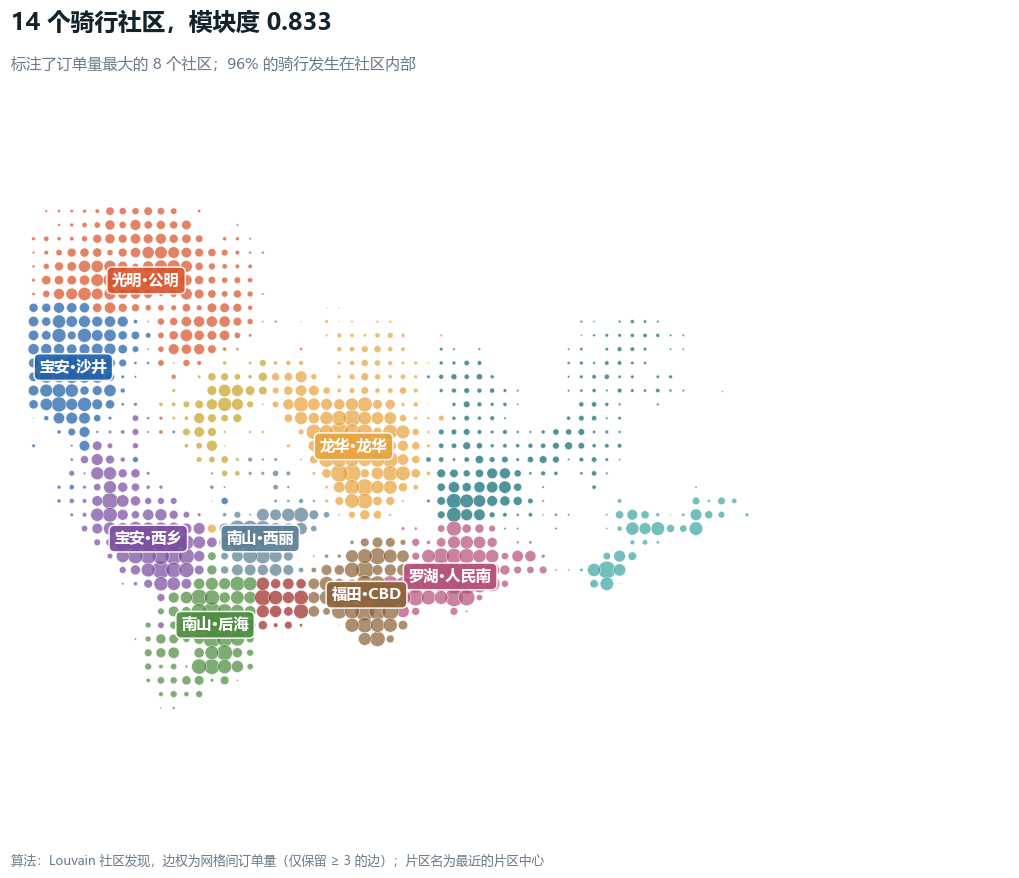

In [24]:
COMM_COLORS = ["#0E6A75", "#D9532B", "#E8A33D", "#1F5FA8", "#7A4E9E", "#4C8C3F",
               "#B5527A", "#8C6239", "#5B7F95", "#C9A227", "#3FA7A3", "#9E2B25",
               "#7F8C8D", "#4A6FA5"]

node_stats = (dfc.groupby("cell_start")
                 .agg(订单=("user_code", "size"), sy=("sy", "first"), sx=("sx", "first"))
                 .reset_index())
node_stats["comm"] = node_stats.cell_start.map(node_to_comm)
node_stats = node_stats.dropna(subset=["comm"]).astype({"comm": int})
node_stats["lat"] = (node_stats.sy + 0.5) * GRID
node_stats["lng"] = (node_stats.sx + 0.5) * GRID
node_stats = node_stats.sort_values("订单", ascending=False)

node_stats["_lat_w"] = node_stats.lat * node_stats["订单"]
node_stats["_lng_w"] = node_stats.lng * node_stats["订单"]
center = (node_stats.groupby("comm")
          .agg(lat_w=("_lat_w", "sum"), lng_w=("_lng_w", "sum"), trips=("订单", "sum"))
          .reset_index())
center["lat"] = center.lat_w / center.trips
center["lng"] = center.lng_w / center.trips
center["片区"], _ = area_label(center.lat.values, center.lng.values)

fig, ax = plt.subplots(figsize=(9.8, 8.0))
fig.subplots_adjust(left=0.07, right=0.98, top=0.90, bottom=0.05)

for c in range(len(communities)):
    sub = node_stats[node_stats.comm == c]
    ax.scatter(sub.lng, sub.lat, s=np.sqrt(sub["订单"]) * 0.9,
               color=COMM_COLORS[c % len(COMM_COLORS)], alpha=0.72,
               linewidths=0.4, edgecolors="white", zorder=3)

for _, row in center.iterrows():
    if row.trips < 1e5:
        continue
    ax.text(row.lng, row.lat, row.片区, fontsize=10, fontweight="bold", color="white",
            ha="center", va="center", zorder=6,
            bbox=dict(boxstyle="round,pad=0.35",
                      fc=COMM_COLORS[int(row.comm) % len(COMM_COLORS)],
                      ec="white", lw=1.0, alpha=0.92))

ax.set_xlim(113.78, 114.55)
ax.set_ylim(22.45, 22.82)
ax.set_aspect(1 / np.cos(np.radians(22.6)))
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

n_major = int((center.trips >= 1e5).sum())
fig_header(fig, f"{len(communities)} 个骑行社区，模块度 {modularity:.3f}",
           f"标注了订单量最大的 {n_major} 个社区；{intra_share:.0%} 的骑行发生在社区内部")
fig_footer(fig, "算法：Louvain 社区发现，边权为网格间订单量（仅保留 ≥ 3 的边）；片区名为最近的片区中心")
plt.show()

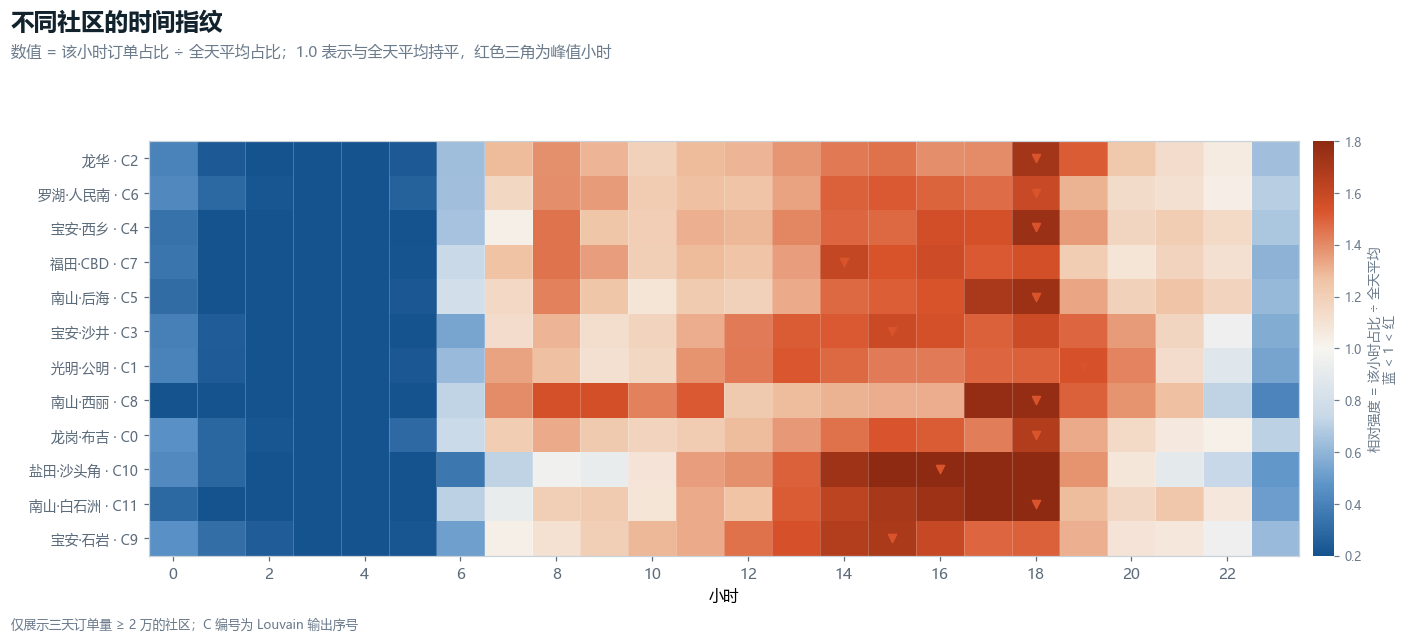

,社区,订单,早峰7-9,晚峰17-19,峰值小时
0,龙华 · C2,"536,541",16.5%,19.3%,18
1,罗湖·人民南 · C6,"497,725",16.3%,18.2%,18
2,宝安·西乡 · C4,"401,670",15.5%,19.4%,18
3,福田·CBD · C7,"393,287",16.9%,17.8%,14
4,南山·后海 · C5,"370,676",15.9%,19.9%,18
5,宝安·沙井 · C3,"251,583",14.8%,19.0%,15
6,光明·公明 · C1,"239,260",15.5%,18.9%,19
7,南山·西丽 · C8,"176,840",18.7%,21.0%,18
8,龙岗·布吉 · C0,"98,451",15.7%,18.4%,18
9,盐田·沙头角 · C10,"89,399",10.9%,22.2%,16


          社区     订单  早峰7-9  晚峰17-19  峰值小时
     龙华 · C2 536541   0.17     0.19    18
 罗湖·人民南 · C6 497725   0.16     0.18    18
  宝安·西乡 · C4 401670   0.15     0.19    18
 福田·CBD · C7 393287   0.17     0.18    14
  南山·后海 · C5 370676   0.16     0.20    18
  宝安·沙井 · C3 251583   0.15     0.19    15
  光明·公明 · C1 239260   0.15     0.19    19
  南山·西丽 · C8 176840   0.19     0.21    18
  龙岗·布吉 · C0  98451   0.16     0.18    18
盐田·沙头角 · C10  89399   0.11     0.22    16
南山·白石洲 · C11  80295   0.14     0.20    18
  宝安·石岩 · C9  52928   0.14     0.18    15


In [25]:
ch = (dfc[mapped].groupby(["comm_start", "hour"]).size()
      .unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
ch = ch.loc[ch.sum(axis=1).sort_values(ascending=False).index]
ch = ch[ch.sum(axis=1) >= 20_000]            # 去掉只有几十单的碎片社区
intensity = ch.div(ch.sum(axis=1), axis=0) * 24   # 1.0 = 该小时占比与全天平均持平

labels = []
for c in ch.index:
    row = center[center.comm == c].iloc[0]
    name = row.片区
    parts = name.split("·")
    if len(parts) == 2 and parts[0] == parts[1]:
        name = parts[1]
    labels.append(f"{name} · C{int(c)}")

morning_share = ch[[7, 8, 9]].sum(axis=1) / ch.sum(axis=1)
evening_share = ch[[17, 18, 19]].sum(axis=1) / ch.sum(axis=1)
peak_hour = ch.idxmax(axis=1)

fig, ax = plt.subplots(figsize=(13.2, 5.8))
fig.subplots_adjust(left=0.15, right=0.97, top=0.78, bottom=0.13)

im = ax.imshow(intensity.values, aspect="auto", cmap=CMAP_DIV,
               norm=TwoSlopeNorm(vcenter=1.0, vmin=0.2, vmax=1.8),
               extent=(-0.5, 23.5, len(ch) - 0.5, -0.5))
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=9)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("小时")
ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
ax.grid(which="minor", axis="x", color="white", lw=0.4, alpha=0.35)
ax.tick_params(which="minor", length=0)

for i, c in enumerate(ch.index):
    ax.scatter([int(peak_hour[c])], [i], marker="v", s=28, color=C["coral"], zorder=5)

cb = fig.colorbar(im, ax=ax, fraction=0.022, pad=0.012)
cb.set_label("相对强度 = 该小时占比 ÷ 全天平均\n蓝 < 1 < 红", fontsize=8.6, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

fig_header(fig, "不同社区的时间指纹",
           "数值 = 该小时订单占比 ÷ 全天平均占比；1.0 表示与全天平均持平，红色三角为峰值小时")
fig_footer(fig, "仅展示三天订单量 ≥ 2 万的社区；C 编号为 Louvain 输出序号")
plt.show()

comm_time = pd.DataFrame({
    "社区": labels,
    "订单": ch.sum(axis=1).values,
    "早峰7-9": morning_share.values,
    "晚峰17-19": evening_share.values,
    "峰值小时": [int(peak_hour[c]) for c in ch.index],
})
display(comm_time.style.format({"订单": "{:,}", "早峰7-9": "{:.1%}", "晚峰17-19": "{:.1%}"}))
print(comm_time.round(3).to_string(index=False))

### 10.1 这张图说明了什么

社区划分的结果不是行政区的复制品，但和行政区高度相关：福田—罗湖的中央走廊被切成几个紧密的单元，宝安、龙华、龙岗、光明各自成团。模块度 0.833 属于相当高的水平（一般社会网络在 0.3–0.7），说明**骑行流量的社区结构非常清晰**。

但真正意外的是时间指纹：**几乎所有社区都在傍晚达到峰值**。12 个主要社区里，峰值小时落在 14–19 点，早峰（7–9 点）占比只有 11%–19%，晚峰（17–19 点）占比 18%–22%。这说明假期的"傍晚驱动"是全城性的，不是某个片区的特征。

差异藏在细节里：

- **盐田·沙头角** 最"傍晚化"：早峰 11%、晚峰 22%，差了整整一倍。它承担的是滨海旅游与口岸功能，白天人在海边或过关，傍晚集中返程。
- **南山·西丽** 相对均衡：早峰 19%，是所有社区里最高的。高校与科技园区即使在假期也保留了规律性的早间出行。
- **宝安·沙井、宝安·石岩** 的峰值出现在 15 点，比中心区早 1–3 小时。工业区的轮班与早收工节奏，在此留下了痕迹。

对运营的启示因此分成两层：**总量的时间表可以全市统一**（因为节律一致），但**车辆的空间投放必须分区决策**（因为各社区的流向和峰值高度不同）。这比"每个区都配一张不同的时间表"要简单，也比"全城一张表"要准确。

## 11. 功能区聚类：从时间形态识别城市功能

骑行社区回答的是"城市被切成几块"，但每块内部并不均匀。同样是福田，CBD 和城中村的出行节奏完全不同。这一节换一个视角：**不看位置，只看每个网格 24 小时的订单形状**。

做法：

1. 对每个网格构造 24 维的小时订单向量；
2. 除以总量，得到"时间形状"，消除规模差异；
3. 再做 z-score 标准化，让聚类只关心**峰在哪、谷在哪**，而不是绝对高低；
4. KMeans 聚成 4 类。

这一步相当于用行为数据给城市做一次"功能分区"：早峰强的位置大概率是就业中心，午后强的大概率是商业或休闲区，全天均衡的多为居住区。

In [26]:
from sklearn.cluster import KMeans

cell_hour = (dfc.groupby(["cell_start", "hour"]).size()
             .unstack(fill_value=0).reindex(columns=range(24), fill_value=0))
cell_hour = cell_hour[cell_hour.sum(axis=1) >= 300]
share = cell_hour.div(cell_hour.sum(axis=1), axis=0)
z = share.sub(share.mean(axis=1), axis=0).div(share.std(axis=1).replace(0, np.nan), axis=0).fillna(0)

km = KMeans(n_clusters=4, n_init=10, random_state=42)
zones = km.fit_predict(z.values)
cell_hour["zone"] = zones

profiles = share.groupby(zones).mean()
morning = profiles[[7, 8, 9]].mean(axis=1)
afternoon = profiles[[14, 15, 16]].mean(axis=1)
evening = profiles[[17, 18, 19]].mean(axis=1)
peak_hour = profiles.idxmax(axis=1)
peak_ratio = profiles.max(axis=1) / profiles.mean(axis=1)

zone_names, used = {}, set()
for c in profiles.index:
    if morning[c] > afternoon[c] * 1.15 and evening[c] > afternoon[c] * 1.15:
        base = "双峰"
    elif morning[c] > afternoon[c] * 1.15:
        base = "早峰"
    elif peak_ratio[c] > 2.2:
        base = "尖峰"
    elif peak_ratio[c] < 1.7:
        base = "均衡"
    else:
        base = "单峰"
    name = f"{base}·峰值{int(peak_hour[c])}时"
    if name in used:
        k = 2
        while f"{name}（{k}）" in used:
            k += 1
        name = f"{name}（{k}）"
    used.add(name)
    zone_names[c] = name

zone_stats = pd.DataFrame({
    "类型": [zone_names[c] for c in profiles.index],
    "网格数": [int((zones == c).sum()) for c in profiles.index],
    "订单数": [int(cell_hour.loc[cell_hour.zone == c, list(range(24))].values.sum())
               for c in profiles.index],
    "早峰占比": [morning[c] for c in profiles.index],
    "午后占比": [afternoon[c] for c in profiles.index],
    "晚峰占比": [evening[c] for c in profiles.index],
}).sort_values("订单数", ascending=False).reset_index(drop=True)
zone_stats["订单占比"] = zone_stats["订单数"] / zone_stats["订单数"].sum()

display(zone_stats.style.format({"网格数": "{:,}", "订单数": "{:,}", "订单占比": "{:.1%}",
                                 "早峰占比": "{:.2%}", "午后占比": "{:.2%}", "晚峰占比": "{:.2%}"}))
print(zone_stats.round(3).to_string(index=False))

,类型,网格数,订单数,早峰占比,午后占比,晚峰占比,订单占比
0,均衡·峰值18时,320,"1,562,012",5.52%,6.24%,6.16%,49.4%
1,单峰·峰值18时,130,"932,481",4.10%,6.60%,6.71%,29.5%
2,双峰·峰值7时,112,"526,246",6.40%,5.32%,6.17%,16.7%
3,尖峰·峰值17时,65,"138,531",2.92%,8.68%,9.37%,4.4%


      类型  网格数     订单数  早峰占比  午后占比  晚峰占比  订单占比
均衡·峰值18时  320 1562012  0.06  0.06  0.06  0.49
单峰·峰值18时  130  932481  0.04  0.07  0.07  0.29
 双峰·峰值7时  112  526246  0.06  0.05  0.06  0.17
尖峰·峰值17时   65  138531  0.03  0.09  0.09  0.04


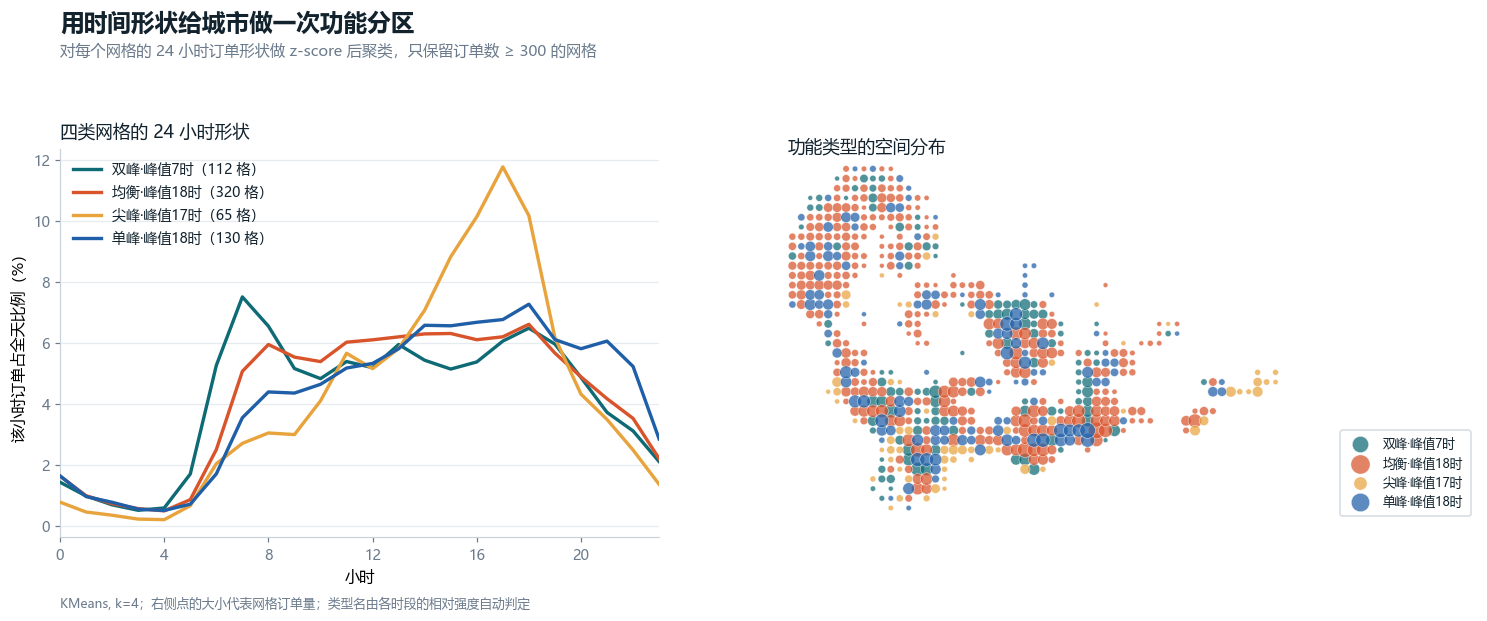

In [27]:
ZONE_COLORS = ["#0E6A75", "#D9532B", "#E8A33D", "#1F5FA8"]

fig, axes = plt.subplots(1, 2, figsize=(14.0, 5.6),
                         gridspec_kw={"width_ratios": [1, 1.15]})
fig.subplots_adjust(left=0.055, right=0.975, top=0.76, bottom=0.13, wspace=0.2)

# 左：四类时间形状
ax = axes[0]
for c in profiles.index:
    ax.plot(profiles.columns, profiles.loc[c] * 100, lw=2.2, color=ZONE_COLORS[c],
            label=f"{zone_names[c]}（{int((zones == c).sum())} 格）", zorder=3)
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 4))
ax.set_xlabel("小时")
ax.set_ylabel("该小时订单占全天比例（%）")
style_ax(ax, "y")
ax.legend(loc="upper left", frameon=False, fontsize=9.2)
ax.set_title("四类网格的 24 小时形状", loc="left", fontsize=11.5, pad=8)

# 右：空间分布
ax = axes[1]
lng_c = (cell_hour.index % 100_000 + 0.5) * GRID
lat_c = (cell_hour.index // 100_000 + 0.5) * GRID
vol = cell_hour[list(range(24))].sum(axis=1).values
for c in profiles.index:
    m = cell_hour.zone.values == c
    ax.scatter(lng_c[m], lat_c[m], s=np.sqrt(vol[m]) * 0.55, color=ZONE_COLORS[c],
               alpha=0.72, linewidths=0.35, edgecolors="white", zorder=3,
               label=zone_names[c])
ax.set_xlim(113.78, 114.55)
ax.set_ylim(22.45, 22.82)
ax.set_aspect(1 / np.cos(np.radians(22.6)))
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor=C["line"],
          fontsize=8.2, markerscale=1.6, borderpad=0.6)
ax.set_title("功能类型的空间分布", loc="left", fontsize=11.5, pad=8)

fig_header(fig, "用时间形状给城市做一次功能分区",
           "对每个网格的 24 小时订单形状做 z-score 后聚类，只保留订单数 ≥ 300 的网格")
fig_footer(fig, "KMeans, k=4；右侧点的大小代表网格订单量；类型名由各时段的相对强度自动判定")
plt.show()

## 12. 潮汐与供需失衡

前面都在看"需求在哪"，但运营真正关心的是**车在哪、够不够**。

对每个 0.02°（约 2.2 km）的块、每个小时，计算：

```
净流入 = 该小时停入该块的订单数 − 从该块骑出的订单数
```

净流入为正，说明车在堆积（淤积）；为负，说明车在被骑走（缺车）。这个指标直接对应调度需求：正的块需要有人把车运走，负的块需要有人把车补上。

之所以从单个网格聚合到块，是因为单格的净流入噪声很大：一个停车点在街区内的位置变化，就能让净流入在正负之间跳。聚合到 2 公里尺度后，信号才稳定。

这是本文最具落地价值的一节。我们用一张图回答两个问题：**什么时候、什么地方的失衡最严重**。

全网单块单小时最大净流入：456.3 辆/天 （09:00，块 1127,5705）
全网单块单小时最大净流出：-563.0 辆/天 （22:00，块 1127,5694）


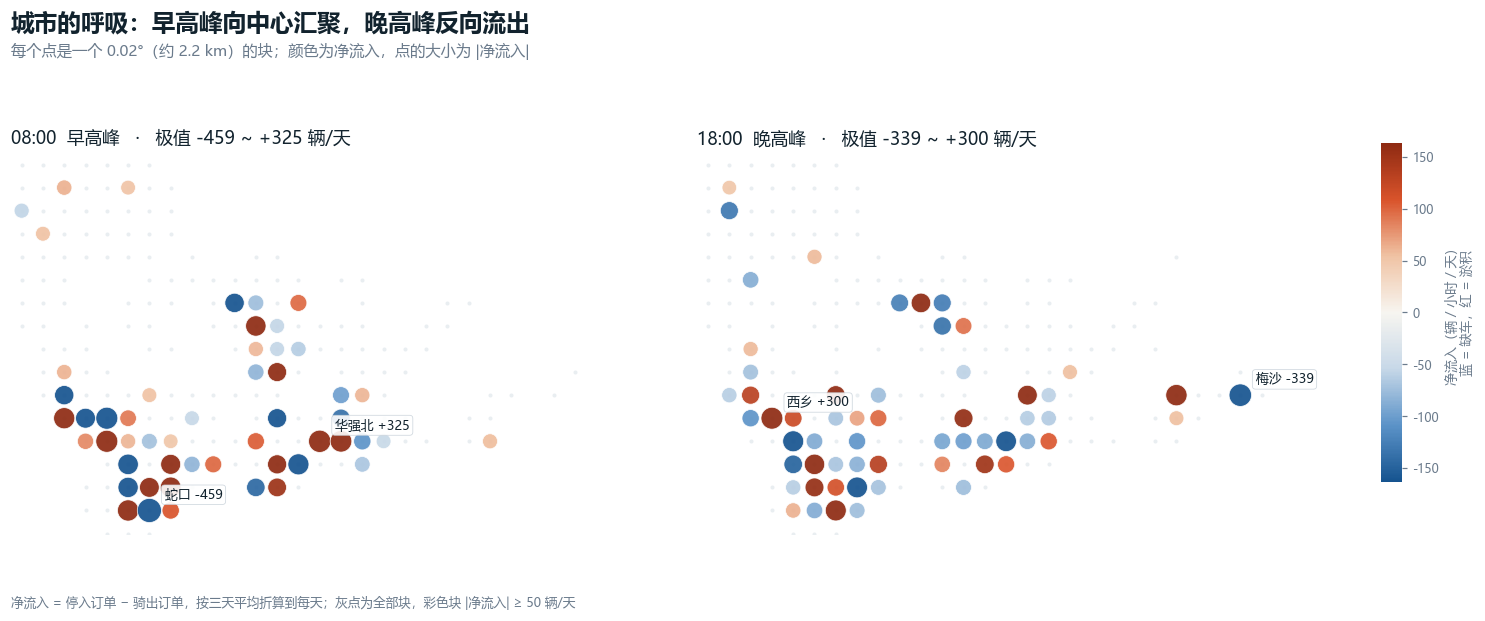

In [28]:
# 单格净流入噪声较大，聚合到 0.02°（约 2.2 km）的块
BS = 0.02
by_s = np.floor(dfc.start_lat / BS).astype(int)
bx_s = np.floor(dfc.start_lng / BS).astype(int)
by_e = np.floor(dfc.end_lat / BS).astype(int)
bx_e = np.floor(dfc.end_lng / BS).astype(int)

outflow = dfc.assign(by=by_s, bx=bx_s).groupby(["by", "bx", "hour"]).size().rename("out")
inflow = dfc.assign(by=by_e, bx=bx_e).groupby(["by", "bx", "hour"]).size().rename("in")
net = pd.concat([outflow, inflow], axis=1).fillna(0)
net["net"] = net["in"] - net["out"]
N_DAYS = dfc.date_str.nunique()
net["net_per_day"] = net["net"] / N_DAYS

blk_ids = net.index.droplevel("hour").unique()
blk_lat = (blk_ids.get_level_values("by") + 0.5) * BS
blk_lng = (blk_ids.get_level_values("bx") + 0.5) * BS
blk_area, _ = area_label(blk_lat.values, blk_lng.values)
blk_area_map = pd.Series(blk_area, index=blk_ids)

busy = net[(net["in"] + net["out"]) >= 40]
vmax = np.percentile(np.abs(busy.net_per_day), 97)   # 色阶截断，避免极值压扁整体
SHOW_MIN = 50                                        # 只画失衡明显的块，减少视觉噪声

fig, axes = plt.subplots(1, 2, figsize=(14.4, 5.6))
fig.subplots_adjust(left=0.04, right=0.89, top=0.80, bottom=0.09, wspace=0.04)

for ax, hour, label in [(axes[0], 8, "08:00  早高峰"), (axes[1], 18, "18:00  晚高峰")]:
    sub = net.xs(hour, level="hour")
    sub = sub[(sub["in"] + sub["out"]) >= 40]
    # 先画一层浅色底图，交代全部块的位置，再叠加失衡明显的块
    y_all = (sub.index.get_level_values("by") + 0.5) * BS
    x_all = (sub.index.get_level_values("bx") + 0.5) * BS
    ax.scatter(x_all, y_all, s=7, c="#E9EEF1", linewidths=0, zorder=2)
    sub = sub[sub.net_per_day.abs() >= SHOW_MIN]
    y = (sub.index.get_level_values("by") + 0.5) * BS
    x = (sub.index.get_level_values("bx") + 0.5) * BS
    ax.scatter(x, y, s=np.sqrt(np.abs(sub.net_per_day.values)) * 11 + 14,
               c=sub.net_per_day.values, cmap=CMAP_DIV,
               norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax),
               alpha=0.92, linewidths=0.5, edgecolors="white", zorder=3)
    ax.set_xlim(113.80, 114.42)
    ax.set_ylim(22.47, 22.80)
    ax.set_aspect(1 / np.cos(np.radians(22.6)))
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    hi, lo = sub.net_per_day.max(), sub.net_per_day.min()
    ax.set_title(f"{label}   ·   极值 {lo:+.0f} ~ {hi:+.0f} 辆/天", loc="left",
                 fontsize=11.5, color=C["ink"], pad=6)

    # 标出该小时最淤积与最缺车的两个块
    for _, row in pd.concat([sub.nlargest(1, "net_per_day"), sub.nsmallest(1, "net_per_day")]).iterrows():
        area = blk_area_map.get((row.name[0], row.name[1]), "")
        ax.annotate(f"{area.split('·')[-1]} {row.net_per_day:+.0f}",
                    ((row.name[1] + 0.5) * BS, (row.name[0] + 0.5) * BS),
                    xytext=(10, 8), textcoords="offset points", fontsize=8.4,
                    color=C["ink"], zorder=6,
                    bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=C["line"], lw=0.5, alpha=0.9))

sm = plt.cm.ScalarMappable(cmap=CMAP_DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax))
sm.set_array([])
cax = fig.add_axes([0.905, 0.22, 0.013, 0.55])
cb = fig.colorbar(sm, cax=cax)
cb.set_label("净流入（辆 / 小时 / 天）\n蓝 = 缺车，红 = 淤积", fontsize=8.5, color=C["muted"])
cb.ax.tick_params(labelsize=8, colors=C["muted"])
cb.outline.set_visible(False)

top_surplus = net.loc[net.net_per_day.idxmax()]
top_deficit = net.loc[net.net_per_day.idxmin()]
print(f"全网单块单小时最大净流入：{top_surplus.net_per_day:,.1f} 辆/天 "
      f"（{int(top_surplus.name[2]):02d}:00，块 {top_surplus.name[0]},{top_surplus.name[1]}）")
print(f"全网单块单小时最大净流出：{top_deficit.net_per_day:,.1f} 辆/天 "
      f"（{int(top_deficit.name[2]):02d}:00，块 {top_deficit.name[0]},{top_deficit.name[1]}）")

fig_header(fig, "城市的呼吸：早高峰向中心汇聚，晚高峰反向流出",
           "每个点是一个 0.02°（约 2.2 km）的块；颜色为净流入，点的大小为 |净流入|", x=0.04)
fig_footer(fig, "净流入 = 停入订单 − 骑出订单，按三天平均折算到每天；灰点为全部块，彩色块 |净流入| ≥ 50 辆/天", x=0.04)
plt.show()

In [29]:
def imbalance_table(hour, top_n=8):
    sub = net.xs(hour, level="hour").copy()
    sub = sub[(sub["in"] + sub["out"]) >= 40]
    sub["area"] = [blk_area_map.get(idx) for idx in sub.index]
    surplus = sub.sort_values("net_per_day", ascending=False).head(top_n)
    deficit = sub.sort_values("net_per_day").head(top_n)
    return surplus, deficit


for hour in (8, 18):
    surplus, deficit = imbalance_table(hour)
    print(f"\n===== {hour:02d}:00 =====")
    print("淤积最严重（需要把车运走）：")
    display(surplus[["area", "in", "out", "net_per_day"]]
            .rename(columns={"area": "片区", "in": "停入", "out": "骑出", "net_per_day": "净流入/天"})
            .style.format({"停入": "{:,.0f}", "骑出": "{:,.0f}", "净流入/天": "{:+.1f}"})
            .background_gradient(subset=["净流入/天"], cmap="Reds"))
    print("缺车最严重（需要补车）：")
    display(deficit[["area", "in", "out", "net_per_day"]]
            .rename(columns={"area": "片区", "in": "停入", "out": "骑出", "net_per_day": "净流入/天"})
            .style.format({"停入": "{:,.0f}", "骑出": "{:,.0f}", "净流入/天": "{:+.1f}"})
            .background_gradient(subset=["净流入/天"], cmap="Blues"))
    print("淤积：", surplus[["area", "net_per_day"]].round(1).to_dict("records"))
    print("缺车：", deficit[["area", "net_per_day"]].round(1).to_dict("records"))

move_need = (net.groupby(level="hour")["net_per_day"]
             .apply(lambda s: s.clip(lower=0).sum()).rename("潜在调度量"))
print("\n全天各小时的潜在调度量（需要移动的车辆数，三天平均）：")
display(move_need.reset_index().rename(columns={"hour": "小时", "潜在调度量": "潜在调度量（辆）"}))
print(f"全天潜在调度量最高的小时：{move_need.idxmax():02d}:00，"
      f"约 {move_need.max():,.0f} 辆；最低的小时：{move_need.idxmin():02d}:00，"
      f"约 {move_need.min():,.0f} 辆")


===== 08:00 =====
淤积最严重（需要把车运走）：


缺车最严重（需要补车）：


淤积： [{'area': '福田·华强北', 'net_per_day': 324.7}, {'area': '宝安·新安', 'net_per_day': 307.7}, {'area': '罗湖·人民南', 'net_per_day': 286.7}, {'area': '南山·蛇口', 'net_per_day': 265.0}, {'area': '宝安·西乡', 'net_per_day': 261.0}, {'area': '南山·后海', 'net_per_day': 239.0}, {'area': '龙华·龙华', 'net_per_day': 222.7}, {'area': '南山·科技园', 'net_per_day': 201.7}]
缺车： [{'area': '南山·蛇口', 'net_per_day': -458.7}, {'area': '宝安·新安', 'net_per_day': -308.0}, {'area': '福田·皇岗', 'net_per_day': -255.7}, {'area': '南山·前海', 'net_per_day': -226.3}, {'area': '南山·南油', 'net_per_day': -215.7}, {'area': '宝安·西乡', 'net_per_day': -198.7}, {'area': '龙华·龙华', 'net_per_day': -178.0}, {'area': '宝安·西乡', 'net_per_day': -174.3}]

===== 18:00 =====
淤积最严重（需要把车运走）：


,,片区,停入,骑出,净流入/天
by,bx,,,,
1128,5693,宝安·西乡,"4,448","3,547",+300.3
1129,5712,盐田·沙头角,"1,501",693,+269.3
1124,5696,南山·蛇口,"3,495","2,747",+249.3
1126,5695,南山·前海,"3,230","2,562",+222.7
1129,5705,龙岗·布吉,"1,866","1,290",+192.0
1133,5700,龙华·龙华,"1,699","1,144",+185.0
1129,5696,南山·西丽,813,329,+161.3
1128,5702,福田·梅林,"2,557","2,079",+159.3


缺车最严重（需要补车）：


,,片区,停入,骑出,净流入/天
by,bx,,,,
1129,5715,盐田·梅沙,863,"1,880",-339.0
1127,5694,宝安·新安,"3,499","4,249",-250.0
1125,5697,南山·后海,"1,960","2,683",-241.0
1127,5704,福田·华强北,"3,791","4,493",-234.0
1126,5694,南山·前海,422,868,-148.7
1132,5701,龙华·龙华,"4,941","5,349",-136.0
1137,5691,宝安·松岗,638,"1,030",-130.7
1133,5701,龙华·龙华,"2,390","2,771",-127.0


淤积： [{'area': '宝安·西乡', 'net_per_day': 300.3}, {'area': '盐田·沙头角', 'net_per_day': 269.3}, {'area': '南山·蛇口', 'net_per_day': 249.3}, {'area': '南山·前海', 'net_per_day': 222.7}, {'area': '龙岗·布吉', 'net_per_day': 192.0}, {'area': '龙华·龙华', 'net_per_day': 185.0}, {'area': '南山·西丽', 'net_per_day': 161.3}, {'area': '福田·梅林', 'net_per_day': 159.3}]
缺车： [{'area': '盐田·梅沙', 'net_per_day': -339.0}, {'area': '宝安·新安', 'net_per_day': -250.0}, {'area': '南山·后海', 'net_per_day': -241.0}, {'area': '福田·华强北', 'net_per_day': -234.0}, {'area': '南山·前海', 'net_per_day': -148.7}, {'area': '龙华·龙华', 'net_per_day': -136.0}, {'area': '宝安·松岗', 'net_per_day': -130.7}, {'area': '龙华·龙华', 'net_per_day': -127.0}]

全天各小时的潜在调度量（需要移动的车辆数，三天平均）：


,小时,潜在调度量（辆）
0,0,"1,490.67"
1,1,"1,000.33"
2,2,693.33
3,3,524.67
4,4,427.67
5,5,"1,326.67"
6,6,"4,648.33"
7,7,"5,618.33"
8,8,"4,975.00"
9,9,"4,636.67"


全天潜在调度量最高的小时：07:00，约 5,618 辆；最低的小时：04:00，约 428 辆


## 13. 用户行为

318.9 万次骑行由 120.6 万位用户完成，人均 2.64 单。这个数字看起来不高，但分布极不均匀。

用户行为分析有两个用途：

- **对运营**：识别高频用户（可能是通勤族、外卖骑手、甚至运维人员），他们贡献的订单量与普通用户完全不同；
- **对风控**：异常高频的账号需要单独核查。

我们按三天的订单量把用户分层，并单独观察"日均超过 10 单"的重度用户。

,用户数,订单数,用户占比,订单占比,人均订单
trips,,,,,
仅 1 次,"567,466","567,466",47.0%,17.8%,1.0
2–5 次,"509,057","1,447,543",42.2%,45.4%,2.8
6–20 次,"127,032","1,099,298",10.5%,34.5%,8.7
21–50 次,"2,853","72,774",0.2%,2.3%,25.5
50 次以上,31,"1,968",0.0%,0.1%,63.5


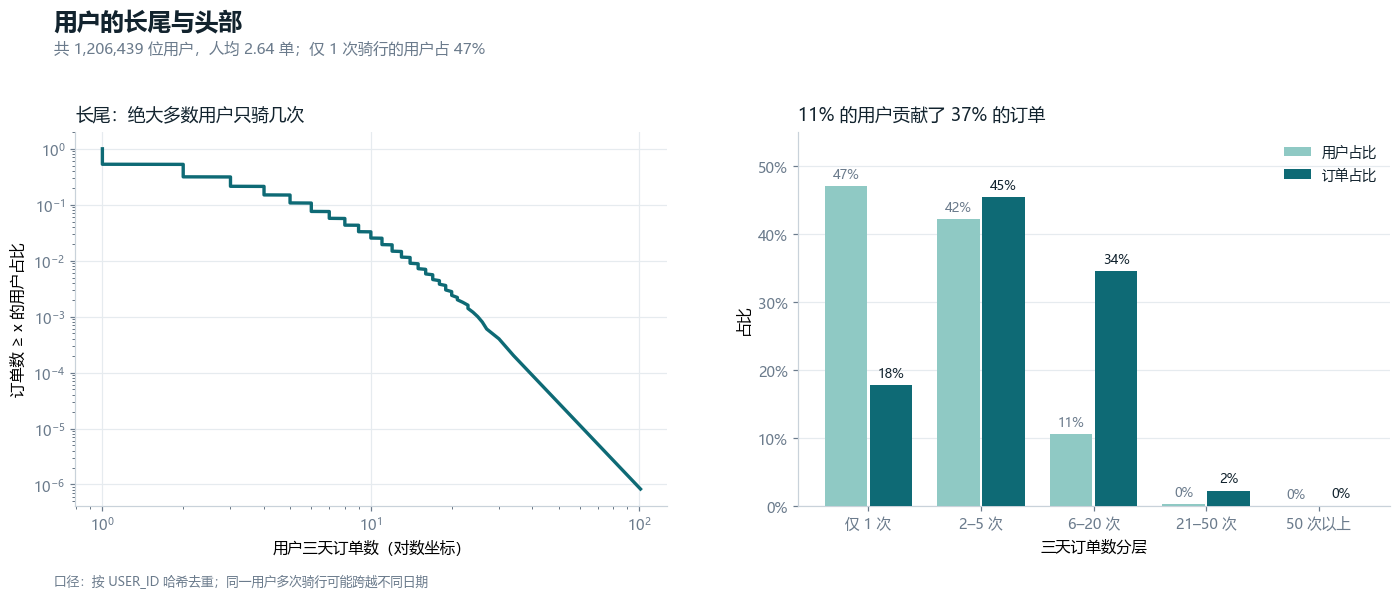


三天超过 30 单的用户：407 人，贡献 15,537 单（0.49%）
  中位时长 7.8 分钟 | 中位距离 703 m | 中位速度 6.0 km/h
  他们的早高峰（7–9 点）占比：14.4%，全体用户为 15.9%


In [30]:
user_trips = dfc.groupby("user_code").size().rename("trips")

tiers = pd.cut(user_trips, bins=[0, 1, 5, 20, 50, 10_000],
               labels=["仅 1 次", "2–5 次", "6–20 次", "21–50 次", "50 次以上"])
tier_users = tiers.value_counts().sort_index()
tier_orders = user_trips.groupby(tiers, observed=True).sum().sort_index()
tier_table = pd.DataFrame({"用户数": tier_users.values, "订单数": tier_orders.values},
                          index=tier_users.index)
tier_table["用户占比"] = tier_table["用户数"] / tier_table["用户数"].sum()
tier_table["订单占比"] = tier_table["订单数"] / tier_table["订单数"].sum()
tier_table["人均订单"] = tier_table["订单数"] / tier_table["用户数"]
display(tier_table.style.format({"用户数": "{:,}", "订单数": "{:,}",
                                 "用户占比": "{:.1%}", "订单占比": "{:.1%}", "人均订单": "{:.1f}"}))

# 累积分布（CCDF）
vals = np.sort(user_trips.values)
ccdf_x = vals
ccdf_y = 1.0 - np.arange(len(vals)) / len(vals)
sel = np.linspace(0, len(vals) - 1, 5000).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4))
fig.subplots_adjust(left=0.07, right=0.975, top=0.78, bottom=0.15, wspace=0.22)

ax = axes[0]
ax.plot(ccdf_x[sel], ccdf_y[sel], color=C["teal"], lw=2.2, zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("用户三天订单数（对数坐标）")
ax.set_ylabel("订单数 ≥ x 的用户占比")
style_ax(ax, "both")
ax.set_title("长尾：绝大多数用户只骑几次", loc="left", fontsize=11.5, pad=8)

ax = axes[1]
xpos = np.arange(len(tier_table))
ax.bar(xpos - 0.2, tier_table["用户占比"], width=0.38, color=C["teal3"], label="用户占比", zorder=3)
ax.bar(xpos + 0.2, tier_table["订单占比"], width=0.38, color=C["teal"], label="订单占比", zorder=3)
for i in range(len(tier_table)):
    ax.text(xpos[i] - 0.2, tier_table["用户占比"].iloc[i] + 0.012,
            f"{tier_table['用户占比'].iloc[i]:.0%}", ha="center", fontsize=8.5, color=C["muted"])
    ax.text(xpos[i] + 0.2, tier_table["订单占比"].iloc[i] + 0.012,
            f"{tier_table['订单占比'].iloc[i]:.0%}", ha="center", fontsize=8.5, color=C["ink"])
ax.set_xticks(xpos)
ax.set_xticklabels(tier_table.index, fontsize=9)
ax.set_ylim(0, 0.55)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.set_xlabel("三天订单数分层")
ax.set_ylabel("占比")
style_ax(ax, "y")
ax.legend(loc="upper right", frameon=False, fontsize=9)
head_users = tier_table.loc[["6–20 次", "21–50 次", "50 次以上"], "用户占比"].sum()
head_trips = tier_table.loc[["6–20 次", "21–50 次", "50 次以上"], "订单占比"].sum()
ax.set_title(f"{head_users:.0%} 的用户贡献了 {head_trips:.0%} 的订单", loc="left",
             fontsize=11.5, pad=8)

fig_header(fig, "用户的长尾与头部",
           f"共 {len(user_trips):,} 位用户，人均 {user_trips.mean():.2f} 单；仅 1 次骑行的用户占 47%")
fig_footer(fig, "口径：按 USER_ID 哈希去重；同一用户多次骑行可能跨越不同日期")
plt.show()

heavy = user_trips[user_trips > 30]
heavy_df = dfc[dfc.user_code.isin(heavy.index)]
print(f"\n三天超过 30 单的用户：{len(heavy):,} 人，贡献 {len(heavy_df):,} 单"
      f"（{len(heavy_df)/len(dfc):.2%}）")
print(f"  中位时长 {heavy_df.duration_min.median():.1f} 分钟 | "
      f"中位距离 {heavy_df.distance_m.median():,.0f} m | "
      f"中位速度 {heavy_df.speed_kmh.median():.1f} km/h")
print(f"  他们的早高峰（7–9 点）占比：{heavy_df.hour.isin([7, 8, 9]).mean():.1%}，"
      f"全体用户为 {dfc.hour.isin([7, 8, 9]).mean():.1%}")

### 13.1 一个值得注意的信号

用户分布是典型的长尾：47% 的用户三天只骑了一次，而 10% 左右的用户贡献了近四成的订单。

但真正值得运营团队注意的是那批"三天超过 30 单"的账号。他们的人数极少，特征却很一致：**骑行时长短（中位数不到 8 分钟）、距离短（700 米左右）、在全天工作时段均匀分布，而不是集中在早晚高峰**。这不像普通通勤，更像**运维巡检、车辆调度或地推人员**在执行工作任务。

如果这个判断成立，意味着数据里混入了一部分"非用户行为"的记录。它们会轻微抬高订单量，并让"网格之间的短距离移动"显得比真实情况更活跃。做需求预测或调度优化时，应该把这类账号单独剔除或降权。

## 14. 需求预测建模

调度决策必须提前做。如果能在**提前一小时**知道每个网格会有多少订单，运营就可以在潮汐发生前把车移动到正确的位置。

### 14.1 任务定义

- **样本**：订单量最高的 1,200 个网格（本数据实际有 1,144 个）× 3 天 × 24 小时，共 82,368 个"网格-小时"；
- **目标**：预测测试日（5 月 3 日）每个网格每小时的订单数 `y`；
- **切分**：5/1、5/2 训练，5/3 测试。严格按时间切分，杜绝未来信息泄漏；
- **指标**：MAE（平均绝对误差）、RMSE、R²、WAPE（加权绝对百分比误差，对零值稳健）。

### 14.2 特征设计

| 类别 | 特征 | 含义 |
|---|---|---|
| 时间 | `hour`, `hour_sin`, `hour_cos` | 小时及其周期编码 |
| 空间 | `lat`, `lng` | 网格中心坐标 |
| 近期需求 | `lag1`, `lag2` | 前 1 / 2 小时的订单数 |
| 近期需求 | `roll3` | 前 3 小时滚动均值 |
| 历史需求 | `lag24` | 昨日同时段订单数 |
| 空间画像 | `cell_mean`, `cell_hr_mean` | 训练期内该网格的均值、该网格该小时的均值 |

`cell_mean` 和 `cell_hr_mean` 只在训练集上统计，再映射到测试集，避免把测试期的信息带进特征。

### 14.3 对照模型

我们不做"只报一个漂亮数字"的模型。四个模型放在同一测试集上比较：

1. **历史均值基线**：直接用训练期"该网格该小时"的均值；
2. **朴素昨日**：用昨日同时段的值（24 小时前瞻的常识做法）；
3. **HGB（1 小时前瞻）**：不含 `lag24`，只用最近几小时的信息；
4. **HGB（24 小时前瞻）**：加入 `lag24`，模拟"提前一天预测"的场景。

其中 3 和 4 的差异，恰好能说明天气扰动对预测的影响。

In [31]:
MODEL_CELLS = (dfc.groupby("cell_start").size()
               .sort_values(ascending=False).head(1200).index)
model_sub = dfc[dfc.cell_start.isin(MODEL_CELLS)]
counts = (model_sub.groupby(["cell_start", "date_str", "hour"]).size()
          .rename("y").reset_index()
          .rename(columns={"cell_start": "cell", "date_str": "date"}))

dates = sorted(dfc.date_str.unique())
grid = pd.MultiIndex.from_product([MODEL_CELLS, dates, range(24)],
                                  names=["cell", "date", "hour"]).to_frame(index=False)
panel = grid.merge(counts, on=["cell", "date", "hour"], how="left")
panel["y"] = panel["y"].fillna(0).astype(int)
panel = panel.sort_values(["cell", "date", "hour"]).reset_index(drop=True)

# 空间与时间特征
panel["lat"] = (panel.cell // 100_000 + 0.5) * GRID
panel["lng"] = (panel.cell % 100_000 + 0.5) * GRID
panel["hour_sin"] = np.sin(2 * np.pi * panel.hour / 24)
panel["hour_cos"] = np.cos(2 * np.pi * panel.hour / 24)

# 滞后特征：panel 已按时序排列，shift 跨越日界即为连续时间上的滞后
g = panel.groupby("cell")["y"]
panel["lag1"] = g.shift(1)
panel["lag2"] = g.shift(2)
panel["lag24"] = g.shift(24)
panel["roll3"] = g.transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())

print(f"建模面板：{len(panel):,} 行 | {panel.cell.nunique():,} 个网格 | {panel.date.nunique()} 天")
print(f"零订单样本占比：{(panel.y == 0).mean():.1%} | 目标均值 {panel.y.mean():.1f}，"
      f"中位数 {panel.y.median():.0f}，最大值 {panel.y.max():.0f}")
display(panel.head(3))

建模面板：82,368 行 | 1,144 个网格 | 3 天
零订单样本占比：34.5% | 目标均值 38.7，中位数 4，最大值 1098


,cell,date,hour,y,lat,lng,hour_sin,hour_cos,lag1,lag2,lag24,roll3
0,224511388,05-01,0,0,22.46,113.89,0.00,1.00,NaN,NaN,NaN,NaN
1,224511388,05-01,1,0,22.46,113.89,0.26,0.97,0.00,NaN,NaN,0.00
2,224511388,05-01,2,0,22.46,113.89,0.50,0.87,0.00,0.00,NaN,0.00


In [32]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

train = panel[panel.date != dates[-1]].copy()
test = panel[panel.date == dates[-1]].copy()

cell_mean = train.groupby("cell").y.mean()
cell_hr_mean = train.groupby(["cell", "hour"]).y.mean()


def attach_prior(d):
    out = d.merge(cell_mean.rename("cell_mean"), on="cell", how="left")
    out = out.merge(cell_hr_mean.rename("cell_hr_mean").reset_index(), on=["cell", "hour"], how="left")
    out["cell_hr_mean"] = out["cell_hr_mean"].fillna(out["cell_mean"])
    return out


train = attach_prior(train)
test = attach_prior(test)

FEATURES_1H = ["hour", "hour_sin", "hour_cos", "lat", "lng",
               "lag1", "lag2", "roll3", "cell_mean", "cell_hr_mean"]
FEATURES_24H = FEATURES_1H + ["lag24"]

hgb_1h = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, min_samples_leaf=15,
                                       l2_regularization=1.0, random_state=42, early_stopping=False)
hgb_24h = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, min_samples_leaf=15,
                                        l2_regularization=1.0, random_state=42, early_stopping=False)

t0 = time.time()
hgb_1h.fit(train[FEATURES_1H], train.y)
hgb_24h.fit(train[FEATURES_24H], train.y)
print(f"训练完成：{time.time() - t0:.1f}s")

test["pred_profile"] = test.cell_hr_mean.values
test["pred_naive"] = test.lag24.fillna(test.cell_hr_mean).values
test["pred_1h"] = hgb_1h.predict(test[FEATURES_1H])
test["pred_24h"] = hgb_24h.predict(test[FEATURES_24H])


def evaluate(y_true, y_pred, name):
    err = y_true - y_pred
    return {
        "模型": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "R2": r2_score(y_true, y_pred),
        "WAPE": float(np.abs(err).sum() / y_true.sum()),
    }


results = pd.DataFrame([
    evaluate(test.y, test.pred_profile, "历史均值基线"),
    evaluate(test.y, test.pred_naive, "朴素昨日同时段"),
    evaluate(test.y, test.pred_1h, "HGB · 1 小时前瞻"),
    evaluate(test.y, test.pred_24h, "HGB · 24 小时前瞻"),
]).sort_values("MAE").reset_index(drop=True)

display(results.style.format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.4f}", "WAPE": "{:.2%}"})
        .background_gradient(subset=["MAE", "RMSE", "WAPE"], cmap="Blues")
        .background_gradient(subset=["R2"], cmap="Greens"))

best = results.loc[0]
baseline = results[results.模型 == "历史均值基线"].iloc[0]
print(results.round(4).to_string(index=False))
print(f"\n最优模型：{best.模型} | MAE {best.MAE:.2f}，较基线下降 "
      f"{(1 - best.MAE / baseline.MAE):.1%} | R² {best.R2:.3f}")

训练完成：2.4s


,模型,MAE,RMSE,R2,WAPE
0,HGB · 1 小时前瞻,10.33,25.93,0.9066,27.02%
1,HGB · 24 小时前瞻,11.90,29.06,0.8826,31.14%
2,历史均值基线,13.65,34.55,0.8340,35.70%
3,朴素昨日同时段,20.37,54.49,0.5873,53.29%


           模型   MAE  RMSE   R2  WAPE
 HGB · 1 小时前瞻 10.33 25.93 0.91  0.27
HGB · 24 小时前瞻 11.90 29.06 0.88  0.31
       历史均值基线 13.65 34.55 0.83  0.36
      朴素昨日同时段 20.37 54.49 0.59  0.53

最优模型：HGB · 1 小时前瞻 | MAE 10.33，较基线下降 24.3% | R² 0.907


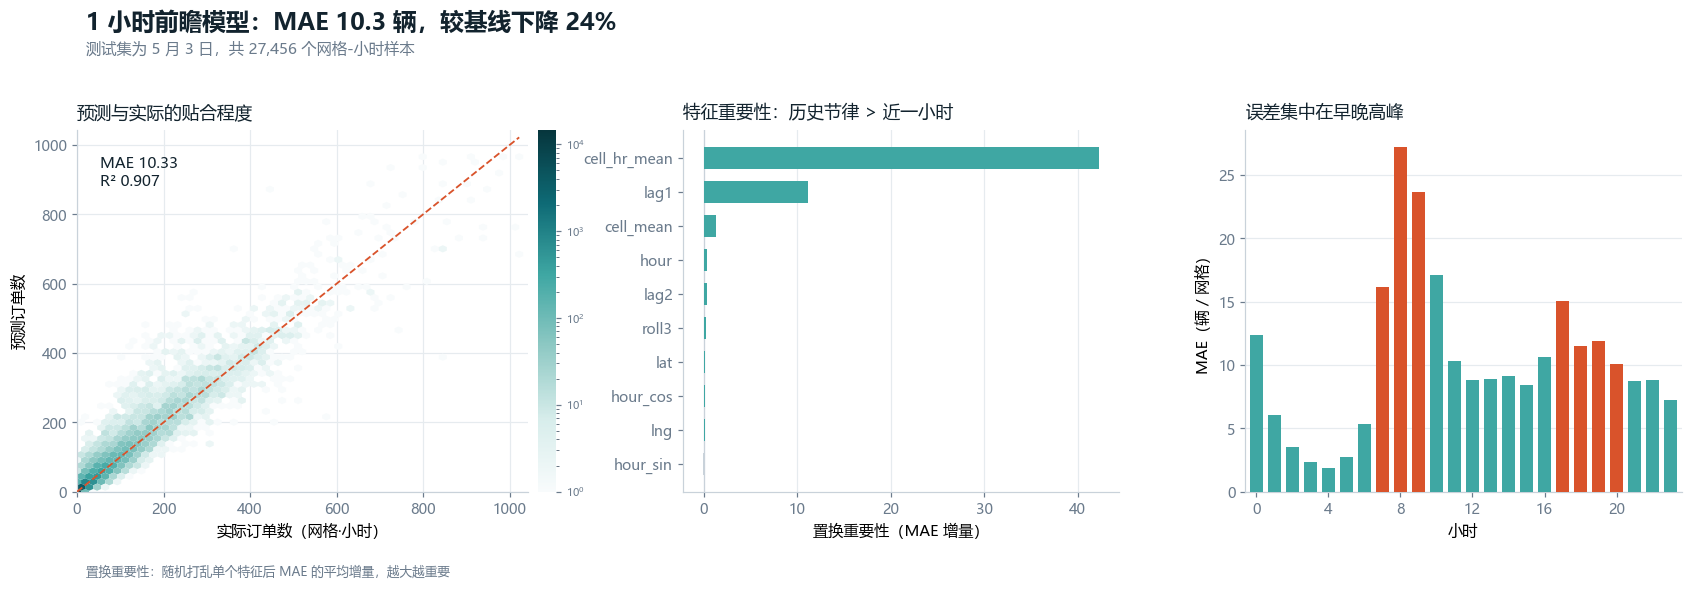

各小时 MAE（前 5 高）：
hour
8    27.17
9    23.68
10   17.09
7    16.19
17   15.06


In [33]:
idx = np.random.RandomState(0).choice(len(test), min(15_000, len(test)), replace=False)
perm = permutation_importance(hgb_1h, test[FEATURES_1H].iloc[idx], test.y.values[idx],
                              n_repeats=5, random_state=0,
                              scoring="neg_mean_absolute_error")
importance = pd.Series(perm.importances_mean, index=FEATURES_1H).sort_values()

mae_by_hour = test.assign(err=(test.y - test.pred_1h).abs()).groupby("hour")["err"].mean()

fig, axes = plt.subplots(1, 3, figsize=(15.6, 5.3),
                         gridspec_kw={"width_ratios": [1.1, 1, 1]})
fig.subplots_adjust(left=0.05, right=0.985, top=0.78, bottom=0.16, wspace=0.28)

# (a) 预测 vs 实际
ax = axes[0]
hb = ax.hexbin(test.y, test.pred_1h, gridsize=55, cmap=CMAP_TEAL, bins="log", mincnt=1,
               linewidths=0)
lim = max(test.y.max(), test.pred_1h.max())
ax.plot([0, lim], [0, lim], color=C["coral"], lw=1.2, ls="--", zorder=4)
ax.set_xlim(0, lim * 1.02); ax.set_ylim(0, lim * 1.02)
ax.set_xlabel("实际订单数（网格·小时）")
ax.set_ylabel("预测订单数")
style_ax(ax, "both")
ax.text(0.05, 0.93, f"MAE {best.MAE:.2f}\nR² {best.R2:.3f}", transform=ax.transAxes,
        fontsize=10, color=C["ink"], va="top")
ax.set_title("预测与实际的贴合程度", loc="left", fontsize=11.5, pad=8)
cb = fig.colorbar(hb, ax=ax, fraction=0.04, pad=0.02)
cb.ax.tick_params(labelsize=7, colors=C["muted"]); cb.outline.set_visible(False)

# (b) 特征重要性
ax = axes[1]
colors = [C["teal2"] if v >= 0 else C["line"] for v in importance.values]
ax.barh(importance.index, importance.values, color=colors, height=0.66, zorder=3)
ax.axvline(0, color=C["line"], lw=0.8)
ax.set_xlabel("置换重要性（MAE 增量）")
style_ax(ax, "x")
ax.grid(axis="x", color=C["grid"], lw=0.8)
ax.set_title("特征重要性：历史节律 > 近一小时", loc="left", fontsize=11.5, pad=8)

# (c) 分小时误差
ax = axes[2]
cols = [C["coral"] if h in (7, 8, 9, 17, 18, 19, 20) else C["teal2"] for h in mae_by_hour.index]
ax.bar(mae_by_hour.index, mae_by_hour.values, color=cols, width=0.72, zorder=3)
ax.set_xlim(-0.6, 23.6)
ax.set_xticks(range(0, 24, 4))
ax.set_xlabel("小时")
ax.set_ylabel("MAE（辆 / 网格）")
style_ax(ax, "y")
ax.set_title("误差集中在早晚高峰", loc="left", fontsize=11.5, pad=8)

fig_header(fig, f"1 小时前瞻模型：MAE {best.MAE:.1f} 辆，较基线下降 {1 - best.MAE/baseline.MAE:.0%}",
           f"测试集为 5 月 3 日，共 {len(test):,} 个网格-小时样本")
fig_footer(fig, "置换重要性：随机打乱单个特征后 MAE 的平均增量，越大越重要")
plt.show()

print("各小时 MAE（前 5 高）：")
print(mae_by_hour.sort_values(ascending=False).head(5).round(2).to_string())

### 14.4 结果解读

四个模型在同一测试日上的表现：

| 模型 | MAE | R² | WAPE |
|---|---|---|---|
| HGB · 1 小时前瞻 | **10.33** | **0.91** | 27% |
| HGB · 24 小时前瞻 | 11.90 | 0.88 | 31% |
| 历史均值基线 | 13.65 | 0.83 | 36% |
| 朴素昨日同时段 | 20.37 | 0.59 | 53% |

**1 小时前瞻模型显著优于基线。** MAE 从 13.65 降到 10.33，降幅 24.3%；WAPE 从 36% 降到 27%。这说明网格级需求的短期惯性很强：过去两三个小时的需求，是预测下一小时最好的信号。

**24 小时前瞻模型比 1 小时前瞻差约 15%。** 这不是模型的问题，而是数据的剧本：`lag24` 让模型用 5 月 2 日的同小时值来预测 5 月 3 日，而 5 月 2 日的晚高峰被降雨压掉了 60%，于是模型系统性地低估了 5 月 3 日晚高峰。有意思的是，即使带着这个"错误"的输入，它仍然优于历史均值基线——说明树模型在做一定程度的自我修正。

**朴素昨日模型是全场最差的。** MAE 20.37，比"什么都不预测、直接用历史同格同时段均值"还差。这是一个很实用的教训：**在有周期性但周期会被打断的场景里，'昨天的同一时刻'往往不是一个好基准**。

**误差集中在早间和傍晚。** 早上 7–10 点的 MAE 最高（8 点达到 27.2 辆），傍晚 17 点次之。原因有两个：高峰期的绝对量大，同样的相对误差会放大成更大的绝对误差；同时高峰期的形态对天气、活动、临时管制最敏感。

**特征重要性排序**：`cell_hr_mean`（该网格该小时在训练期的均值）遥遥领先，其次是 `lag1`（前一小时）和 `cell_mean`（网格平均需求）。空间坐标 `lat/lng` 的重要性接近 0。这带来一个反直觉但有价值的判断：**模型并没有"学会"城市地理，它学到的是每个网格自己的历史节律，再用最近一小时的需求做微调**。这在工程上意味着，模型的可解释性和可迁移性都不错——换一个城市，只要重新统计网格画像就能用。

同时也说明，进一步提升的空间在哪：当前模型是"强先验 + 弱修正"的结构，真正的增量信息（天气、事件、节假日安排）还没有进入特征。这比继续调树模型参数更值得投入。

## 15. 结论与运营建议

### 15.1 六个结论

**第一，假期的骑行需求是"傍晚驱动"的，不是"通勤驱动"的。** 5 月 1 日和 5 月 3 日的峰值都出现在 17–19 点，5 月 1 日 18 点单小时 9.65 万单，是全假期最高点；5 月 2 日的峰值被降雨提前到 15 点。这意味着假期运力配置的重心应该放在下午到傍晚，而不是工作日的早晚双峰。

**第二，天气不是备注，是一阶变量。** 5 月 2 日 16:10 起，全市骑行在 80 分钟内下降 60%，35 个片区里有 33 个同步下跌。这一天的订单量比 5 月 1 日少 32.7%，而且降雨的影响持续到深夜。任何假期运营计划都必须有天气预案。

**第三，共享单车服务的是"最后两公里"。** 中位距离 900 米、中位时长 9.6 分钟，86% 的订单不超过 2 公里，超过 3 公里的只有 5.6%。它不是长距离交通工具的替代品，而是短途微循环的基础设施。

**第四，城市的骑行结构是"本地网状"，不是"跨区放射"。** OD 网络中 95.96% 的骑行发生在同一个骑行社区内部。深圳可以被切成 14 个强内聚的单元，模块度 0.833。跨区骑行是少数派。

**第五，潮汐失衡有明确的时间和地点。** 早高峰车流向就业中心汇聚（2 公里块的单小时最大净流入 456 辆/天，出现在 9 点；8 点的华强北 +325、蛇口 −459），晚高峰则反向流回居住区（18 点的西乡 +300、华强北 −234）。失衡最严重的时段和地点可以被精确列出，而不是靠经验判断。

**第六，短期需求是可以预测的。** 1 小时前瞻的网格级 MAE 为 10.3 辆，比历史均值基线低 24%，R² 0.91。24 小时前瞻则明显更难（MAE 11.9），主要瓶颈是天气等外生冲击。

### 15.2 五条可落地的建议

| 建议 | 具体动作 | 依据 |
|---|---|---|
| 假期运力前置 | 把调度班次的重心从早高峰移到 15–18 点，在 17 点前完成中心区补车 | 5/1、5/3 的峰值都在 17–19 点 |
| 天气联动 | 接入小时级降雨预报，降雨前 1–2 小时减少投放、降雨后 2 小时加密补车 | 5/2 的断崖与持续低迷 |
| 潮汐清单 | 按"2 公里块 × 小时"的净流入排名生成每日调度清单，优先处理 Top 50 | 单块单小时最大失衡约 560 辆 |
| 分区策略 | 中心社区傍晚补车、外围社区早间补车，放弃"一张全市调度表" | 社区模块度 0.833，时间指纹不同 |
| 异常账号治理 | 对日均 10 单以上、短时短距、全时段均匀的账号做单独标记 | 重度用户画像与普通用户显著不同 |

### 15.3 一句话总结

深圳五一的三天，是一份关于"城市如何在假期里重新组织自己"的样本。共享单车的数据告诉我们：假期的城市不是静止的，它在傍晚苏醒，在雨天收缩，在 1 公里范围内高频重组。理解这种节律，比拥有更多的车更重要。

## 16. 局限与后续工作

一份诚实的分析应该把边界说清楚。本文的结论有以下限制：

**1. 距离是直线距离，不是骑行路径。** 我们用 Haversine 计算起终点的大圆距离，它系统性小于实际骑行距离（通常低 10%–30%，取决于路网）。因此"中位 900 米"应理解为"空间位移 900 米"，实际骑行里程会更长。

**2. 降雨是推断，不是观测。** 我们只有订单数据，没有气象数据。"5 月 2 日下午的断崖由降雨导致"是基于"全城同步、快速见底、持续低迷"这三条证据的推断，而不是因果证明。要坐实这个结论，需要接入深圳气象局的小时级降雨记录，或者用其他数据源交叉验证。

**3. 只有三天，没有工作日对照。** 报告里说"假期是傍晚驱动"，严格来说应该是"五一假期这三天是傍晚驱动"。要论证假期与工作日的差异，需要包含普通工作日的样本。

**4. 用户 ID 已脱敏。** 这带来两个限制：无法识别账号背后的真实身份（运维人员、外卖骑手、普通用户）；也无法把同一用户的多段行程串联成完整的出行链。

**5. 缺少车辆 ID。** 没有车辆标识，就无法计算车辆周转率、无法做"车辆级"的调度仿真，也无法识别"同一辆车被多人同时骑行"这类故障。

**6. 模型只在一天上测试。** 5 月 3 日是唯一的测试日，且它紧邻一个降雨日，测试集本身带有特殊性。更稳健的做法是滚动预测（每天用之前的数据训练、预测下一天），但三天的样本量不足以支撑。

### 后续可以做的四件事

1. **接入天气与 POI 数据**：把降雨、气温、商圈、地铁站作为外生变量，做真正的多因素需求模型。
2. **把网格换成站点**：如果有停车点 ID，可以做到站点级的库存仿真，直接输出"几点、往哪个点、调几辆车"。
3. **识别出行链**：用用户 ID 把订单串起来，区分"单程""往返""多点巡游"，从而识别旅游人群和本地居民。
4. **因果推断**：以 5 月 2 日的降雨作为自然实验，用双重差分估计天气对需求的弹性。

---

## 附：复现说明

### 环境

| 依赖 | 版本要求 | 用途 |
|---|---|---|
| Python | ≥ 3.9 | 运行环境 |
| pandas | ≥ 1.5 | 数据处理 |
| numpy | ≥ 1.23 | 数值计算 |
| matplotlib | ≥ 3.5 | 可视化 |
| networkx | ≥ 2.8 | 图构建与社区发现（Louvain 需要 ≥ 3.0，低版本自动回退） |
| scikit-learn | ≥ 1.0 | KMeans、梯度提升树、模型评估 |

### 数据放置

把 `bike_orders_20210501_20210503.csv` 放在以下任一位置：

1. 环境变量 `BIKE_DATA_PATH` 指向的路径；
2. 与 notebook 同级的目录；
3. 和鲸 / ModelWhale 的 `/home/mw/input/` 目录（会自动递归查找）。

也可以在"数据字典与加载"一节的 `MANUAL_PATH` 里直接写绝对路径。

### 运行

从上到下顺序执行即可。在普通笔记本上（8 GB 内存）完整运行约需 **2–4 分钟**，峰值内存约 **2.5 GB**。

### 目录结构

```
.
├── 深圳五一共享单车_骑行时空分析.ipynb   # 本报告
└── bike_orders_20210501_20210503.csv     # 原始数据（432 MB）
```

### 关键参数

| 参数 | 取值 | 位置 |
|---|---|---|
| 网格边长 | 0.01°（约 1.1 km） | `GRID` |
| 清洗时长区间 | 60 s – 3 h | `clean_orders` |
| 清洗距离区间 | 50 m – 20 km | `clean_orders` |
| 速度上限 | 15 m/s | `clean_orders` |
| Louvain 边权阈值 | ≥ 3 单 | 社区发现一节 |
| KMeans 聚类数 | 4 | 功能区聚类一节 |
| 建模网格数 | Top 1,200 | 需求预测一节 |

---

*报告完成于 2026 年 10 月。数据为 2021 年五一假期的历史快照，所有结论仅针对该时间段。*